# Portafolio óptimo y cobertura con futuros sobre el S&P 500

**Acciones:** Microsoft (MSFT), JPMorgan Chase (JPM) y Coca-Cola (KO)  
**Índice de referencia:** S&P 500 (^GSPC)  
**Capital:** USD 20.000.000 | **Inicio:** 30/04/2026 | **Horizonte:** 4 años  
**Histórico:** 10 años diarios (30/04/2016 – 30/04/2026) | **Año comercial:** 252 días

In [71]:
!pip -q install yfinance

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

pd.set_option('display.float_format', lambda x: f'{x:,.6f}')

# Parámetros del caso
TICKERS  = ['MSFT', 'JPM', 'KO']
INDICE   = '^GSPC'          # S&P 500 (portafolio de mercado para CAPM)
INICIO   = '2016-04-30'     # 10 años de histórico
FIN      = '2026-05-01'     # yfinance excluye la fecha final -> incluye el 30/04/2026
CAPITAL  = 20_000_000       # USD
DIAS_ANO = 252              # año comercial
DIAS_MES = 21               # 252 / 12

## 1. Descarga de datos

Se usan precios de cierre **ajustados** por dividendos y splits, de modo que los retornos reflejan el rendimiento total de cada acción. Los dividendos se descargan por separado para la pregunta 11.

In [73]:
precios = yf.download(TICKERS + [INDICE], start=INICIO, end=FIN,
                      auto_adjust=True, progress=False)['Close']
precios = precios[TICKERS + [INDICE]].dropna()

print('Primera fecha:', precios.index.min().date())
print('Última fecha :', precios.index.max().date())
print('Observaciones:', len(precios))
print('Datos faltantes por serie:')
print(precios.isna().sum())

precios.to_csv('precios_ajustados.csv')
precios.tail()

Primera fecha: 2016-05-02
Última fecha : 2026-04-30
Observaciones: 2514
Datos faltantes por serie:
Ticker
MSFT     0
JPM      0
KO       0
^GSPC    0
dtype: int64


Ticker,MSFT,JPM,KO,^GSPC
Date,,,,
2026-04-24,422.906189,305.373962,75.686798,"7,165.080078"
2026-04-27,423.105377,308.692383,74.511444,"7,173.910156"
2026-04-28,427.517487,308.514099,77.385620,"7,138.799805"
2026-04-29,422.746826,306.334808,77.899223,"7,135.950195"
2026-04-30,406.134155,310.277313,77.790581,"7,209.009766"


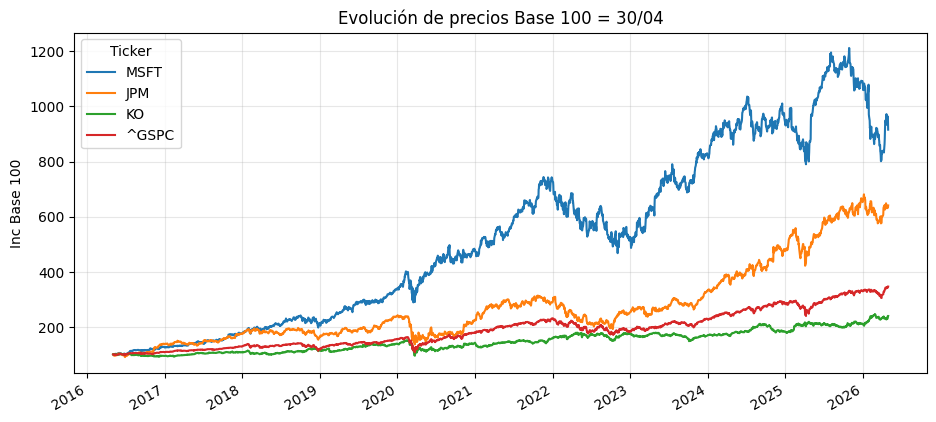

,Precio el 30/04/2026,Var. último año,Var. 10 años
Ticker,,,
MSFT,406.134155,3.957341,815.718072
JPM,310.277313,30.537859,540.686248
KO,77.790581,11.706620,139.545168
^GSPC,"7,209.009766",29.447513,246.348904


In [74]:
# Evolución de precios en base 100
base100 = precios / precios.iloc[0] * 100
ax = base100.plot(figsize=(11, 5), title='Evolución de precios Base 100 = 30/04')
ax.set_ylabel('Inc Base 100'); ax.set_xlabel('')
plt.grid(alpha=0.3); plt.show()

# Precio al inicio de la inversión y variación en el último año
resumen = pd.DataFrame({
    'Precio el 30/04/2026': precios.iloc[-1],
    'Var. último año ': (precios.iloc[-1] / precios.iloc[-DIAS_ANO] - 1) * 100,
    'Var. 10 años ': (precios.iloc[-1] / precios.iloc[0] - 1) * 100,
})
resumen

In [75]:
# Dividendos por acción pagados
dividendos = {}
for t in TICKERS:
    d = yf.Ticker(t).dividends
    d.index = d.index.tz_localize(None)
    dividendos[t] = d.loc[INICIO:'2026-04-30']

div_anual = pd.DataFrame({t: d.groupby(d.index.year).sum() for t, d in dividendos.items()})
div_anual.index.name = 'Año'
div_anual.to_csv('dividendos_anuales.csv')
div_anual

,MSFT,JPM,KO
Año,,,
2016,1.110000,0.960000,1.050000
2017,1.590000,2.040000,1.480000
2018,1.720000,2.480000,1.560000
2019,1.890000,3.300000,1.600000
2020,2.090000,3.600000,1.640000
2021,2.300000,3.700000,1.680000
2022,2.540000,4.000000,1.760000
2023,2.790000,4.050000,1.840000
2024,3.080000,4.600000,1.940000


## 2. Retornos, volatilidad, covarianzas y correlaciones

**Frecuencia:** diaria (precios de cierre ajustados).  
**Retorno periódico:** retorno simple diario. Se usa el retorno simple porque el retorno de un portafolio es el promedio ponderado de los retornos simples de sus activos, condición que requiere la optimización de la pregunta 3.  
**Anualización (año comercial de 252 días):**

La raíz de 252 en la volatilidad se explica porque, si los retornos diarios son independientes, la **varianza** crece proporcionalmente al tiempo y la desviación estándar lo hace con su raíz cuadrada.

In [76]:
# 2.1 Retornos periódicos
retornos = precios.pct_change().dropna()
ret_acc  = retornos[TICKERS]

print('Conteo de retornos:', len(retornos))
retornos.to_csv('retornos_diarios.csv')
retornos.head()

Conteo de retornos: 2513


Ticker,MSFT,JPM,KO,^GSPC
Date,,,,
2016-05-03,-0.016400,-0.019282,-0.003113,-0.008677
2016-05-04,0.001808,-0.015825,0.003122,-0.005937
2016-05-05,0.001404,-0.005360,0.001779,-0.000239
2016-05-06,0.009011,0.005878,0.005770,0.003175
2016-05-09,-0.006351,-0.006331,-0.001765,0.000753


In [77]:
# 2.2 Estadísticas diarias y anualizadas
anios = (precios.index[-1] - precios.index[0]).days / 365.25

estad = pd.DataFrame({
    'Retorno medio diario':           retornos.mean(),
    'Desv. estándar diaria':          retornos.std(),
    'Retorno anual promedio':         retornos.mean() * DIAS_ANO,
    'Desv. estándar anualizada':      retornos.std() * np.sqrt(DIAS_ANO),
    'Retorno compuesto anual (CAGR)': (precios.iloc[-1] / precios.iloc[0]) ** (1 / anios) - 1,
})
estad['Retorno / riesgo'] = estad['Retorno anual promedio'] / estad['Desv. estándar anualizada']
estad.to_csv('estadisticas_anualizadas.csv')

tabla = estad.copy()
for c in ['Retorno anual promedio', 'Desv. estándar anualizada', 'Retorno compuesto anual (CAGR)']:
    tabla[c] = tabla[c] * 100
tabla.rename(columns={'Retorno anual promedio': 'Retorno anual promedio (%)',
                      'Desv. estándar anualizada': 'Desv. estándar anualizada (%)',
                      'Retorno compuesto anual (CAGR)': 'CAGR (%)'}).round(4)

,Retorno medio diario,Desv. estándar diaria,Retorno anual promedio (%),Desv. estándar anualizada (%),CAGR (%),Retorno / riesgo
Ticker,,,,,,
MSFT,0.001000,0.017000,25.839600,26.919300,24.807900,0.959900
JPM,0.000900,0.017200,22.367600,27.363000,20.425900,0.817400
KO,0.000400,0.011400,10.414900,18.142800,9.135200,0.574100
^GSPC,0.000600,0.011400,14.097300,18.065300,13.237000,0.780400


In [78]:
# 2.3 Matriz de varianzas y covarianzas (diaria y anualizada)
cov_diaria = ret_acc.cov()
cov_anual  = cov_diaria * DIAS_ANO
cov_anual.to_csv('matriz_covarianzas_anual.csv')

print('Matriz de varianzas y covarianzas diaria')
display(cov_diaria)
print('Matriz de varianzas y covarianzas anualizada')
display(cov_anual)

Matriz de varianzas y covarianzas diaria


Ticker,MSFT,JPM,KO
Ticker,,,
MSFT,0.000288,0.000123,0.000064
JPM,0.000123,0.000297,0.000079
KO,0.000064,0.000079,0.000131


Matriz de varianzas y covarianzas anualizada


Ticker,MSFT,JPM,KO
Ticker,,,
MSFT,0.072465,0.031039,0.016108
JPM,0.031039,0.074873,0.019989
KO,0.016108,0.019989,0.032916


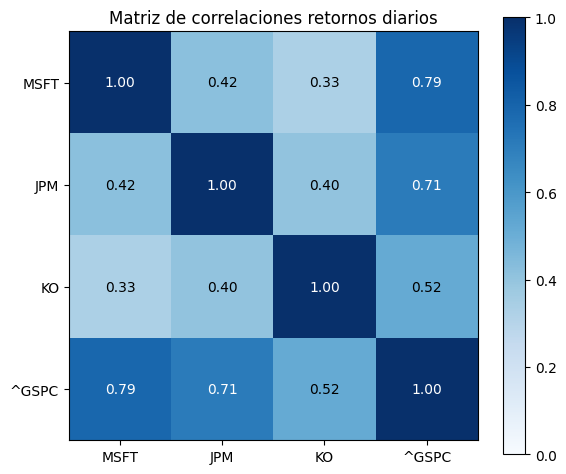

Ticker,MSFT,JPM,KO,^GSPC
Ticker,,,,
MSFT,1.000000,0.421400,0.329800,0.788100
JPM,0.421400,1.000000,0.402600,0.708300
KO,0.329800,0.402600,1.000000,0.516700
^GSPC,0.788100,0.708300,0.516700,1.000000


In [79]:
# 2.4 Matriz de correlaciones accion e indice
corr = retornos.corr()
corr.to_csv('matriz_correlaciones.csv')

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center',
                color='white' if corr.iloc[i, j] > 0.6 else 'black')
plt.colorbar(im); ax.set_title('Matriz de correlaciones retornos diarios')
plt.tight_layout(); plt.show()

corr.round(4)

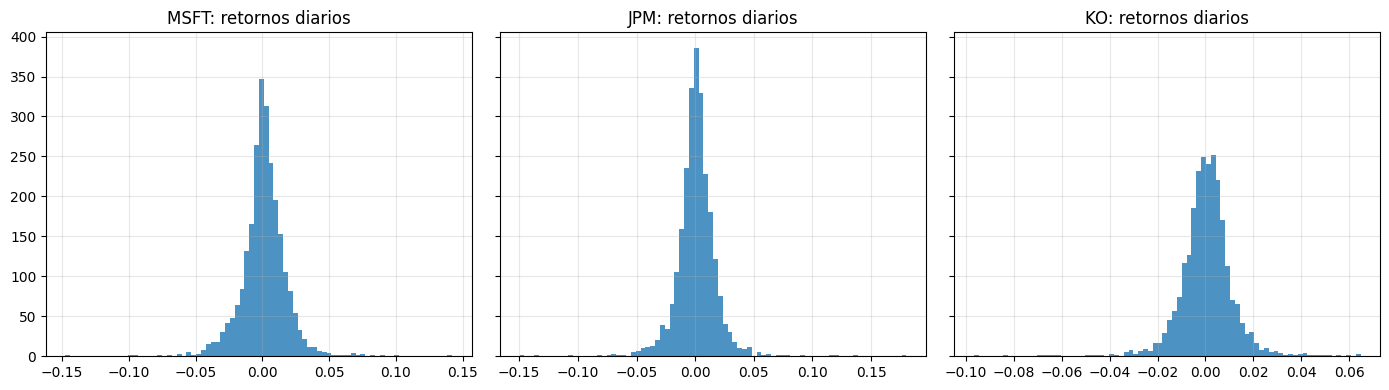

In [80]:
# 2.5 Distribución de retornos diarios
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, t in zip(axes, TICKERS):
    ax.hist(ret_acc[t], bins=80, alpha=0.8)
    ax.set_title(f'{t}: retornos diarios'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

3. (Portafolio óptimo de media-varianza)
Criterio de optimalidad: portafolio de máximo Sharpe Ratio (portafolio tangente de Markowitz), que es el que ofrece el mayor retorno en exceso de la tasa libre de riesgo por cada unidad de riesgo:



Retornos anuales promedio; Matriz de covarianzas anualizada.
Restricción: sin ventas en corto, porque el mandato es invertir en acciones.
Tasa libre de riesgo ( rf ): rendimiento del Treasury a 5 años (^FVX) al 30/04/2026, el plazo más cercano al horizonte de 4 años.
Como referencia también se calcula el portafolio de mínima varianza y la frontera eficiente.

In [81]:
# 3.1 Tasa libre de riesgo
from scipy.optimize import minimize

tasas = yf.download(['^FVX', '^TNX', '^IRX'], start='2026-04-01', end=FIN,
                    auto_adjust=False, progress=False)['Close'].dropna()
tasas_inicio = tasas.loc[:'2026-04-30'].iloc[-1]
print('Fecha tasa:', tasas.loc[:'2026-04-30'].index[-1].date())
print('Rendimientos anual:')
print(tasas_inicio.rename({'^IRX': 'T-Bill 13 semanas',
                           '^FVX': 'Treasury 5 años',
                           '^TNX': 'Treasury 10 años'}).round(4))

RF = tasas_inicio['^FVX'] / 100      # tasa usada en el ejercicio
print(f'\nTasa libre de riesgo usada (Treasury 5 años): {RF:.4%}')

Fecha tasa: 2026-04-30
Rendimientos anual:
Ticker
Treasury 5 años     4.023000
T-Bill 13 semanas   3.585000
Treasury 10 años    4.390000
Name: 2026-04-30 00:00:00, dtype: float64

Tasa libre de riesgo usada (Treasury 5 años): 4.0230%


In [82]:
# 3.2 Funciones del portafolio
mu    = ret_acc.mean() * DIAS_ANO
Sigma = cov_anual.values
n     = len(TICKERS)

def ret_port(w):  return w @ mu.values
def vol_port(w):  return np.sqrt(w @ Sigma @ w)
def sharpe(w):    return (ret_port(w) - RF) / vol_port(w)

restricciones = ({'type': 'eq', 'fun': lambda w: w.sum() - 1},)
W_MIN = 0.10                       # peso mínimo por acción ajuste realizado
limites_libre = [(0, 1)] * n       # sin restricción
limites = [(W_MIN, 1)] * n         # con peso mínimo de 10%
w0 = np.ones(n) / n

# Portafolio óptimo SIN restricción: asigna 0% a KO
opt_libre = minimize(lambda w: -sharpe(w), w0, bounds=limites_libre, constraints=restricciones)
w_libre = opt_libre.x

# Portafolio óptimo FINAL (máximo Sharpe con peso mínimo de 10%)
opt = minimize(lambda w: -sharpe(w), w0, bounds=limites, constraints=restricciones)
w_opt = opt.x

# Portafolio de mínima varianza (referencia)
mv = minimize(vol_port, w0, bounds=limites, constraints=restricciones)
w_mv = mv.x

print('Optimización exitosa:', opt.success, '|', opt_libre.success, '|', mv.success)

Optimización exitosa: True | True | True


In [83]:
# 3.3 Resultados: pesos, montos y métricas
def resumen_port(w, nombre):
    return pd.Series({
        **{f'Peso {t}': w[i] for i, t in enumerate(TICKERS)},
        'Retorno esperado anual': ret_port(w),
        'Desv. estándar anual':   vol_port(w),
        'Sharpe Ratio':           sharpe(w),
    }, name=nombre)

w_eq = np.ones(n) / n
comparacion = pd.concat([resumen_port(w_opt, 'Óptimo con mín. 10% (final)'),
                         resumen_port(w_libre, 'Óptimo sin restricción'),
                         resumen_port(w_mv,  'Mínima varianza'),
                         resumen_port(w_eq,  'Pesos iguales')], axis=1)

asignacion = pd.DataFrame({
    'Peso óptimo (%)':   w_opt * 100,
    'Monto (USD)':       w_opt * CAPITAL,
    'Precio 30/04/2026': precios[TICKERS].iloc[-1].values,
}, index=TICKERS)
asignacion['Acciones (aprox.)'] = (asignacion['Monto (USD)'] / asignacion['Precio 30/04/2026']).round(0)
asignacion.loc['Total'] = [asignacion['Peso óptimo (%)'].sum(), asignacion['Monto (USD)'].sum(), np.nan, np.nan]

asignacion.to_csv('asignacion_optima.csv'); comparacion.to_csv('comparacion_portafolios.csv')
print('ASIGNACIÓN DEL PORTAFOLIO ÓPTIMO (USD 20.000.000)')
display(asignacion.round(2))
print('COMPARACIÓN DE PORTAFOLIOS')
display(comparacion.round(4))

# Variables que usan las preguntas siguientes
W_OPT, RET_P, VOL_P = w_opt, ret_port(w_opt), vol_port(w_opt)

ASIGNACIÓN DEL PORTAFOLIO ÓPTIMO (USD 20.000.000)


,Peso óptimo (%),Monto (USD),Precio 30/04/2026,Acciones (aprox.)
MSFT,56.790000,"11,357,120.210000",406.130000,"27,964.000000"
JPM,33.210000,"6,642,879.790000",310.280000,"21,409.000000"
KO,10.000000,"2,000,000.000000",77.790000,"25,710.000000"
Total,100.000000,"20,000,000.000000",NaN,NaN


COMPARACIÓN DE PORTAFOLIOS


,Óptimo con mín. 10% (final),Óptimo sin restricción,Mínima varianza,Pesos iguales
Peso MSFT,0.567900,0.620300,0.184500,0.333300
Peso JPM,0.332100,0.379700,0.115700,0.333300
Peso KO,0.100000,0.000000,0.699900,0.333300
Retorno esperado anual,0.231400,0.245200,0.146400,0.195400
Desv. estándar anual,0.216400,0.230900,0.168300,0.186900
Sharpe Ratio,0.883700,0.887900,0.631200,0.830100


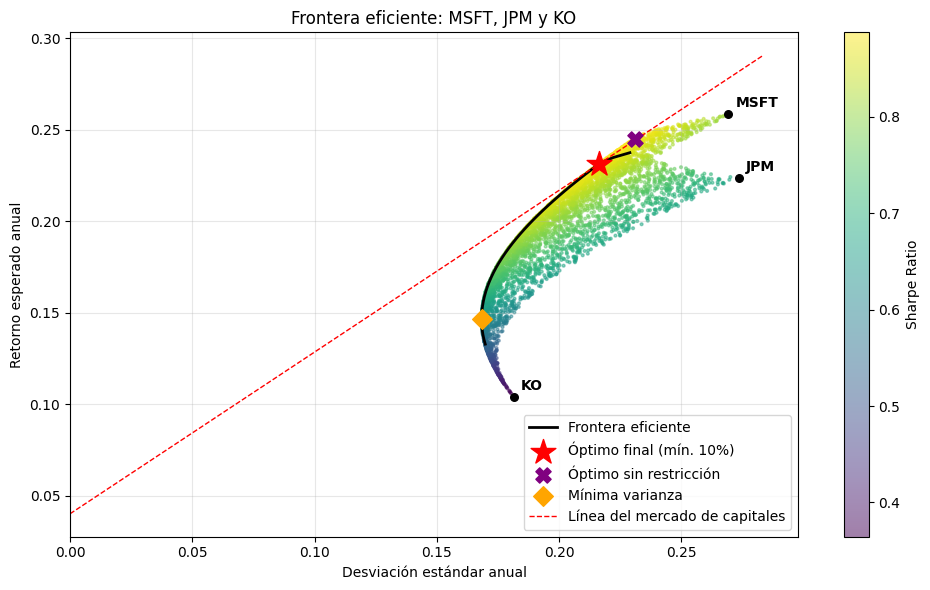

In [84]:
# 3.4 Frontera eficiente y ubicación del portafolio óptimo
objetivos = np.linspace(mu.min(), mu.max(), 60)
vols_frontera = []
for r_obj in objetivos:
    res = minimize(vol_port, w0, bounds=limites,
                   constraints=restricciones + ({'type': 'eq', 'fun': lambda w, r=r_obj: ret_port(w) - r},))
    vols_frontera.append(res.fun if res.success else np.nan)

# Portafolios aleatorios
rng = np.random.default_rng(42)
W_rand = rng.dirichlet(np.ones(n), 5000)
r_rand = W_rand @ mu.values
v_rand = np.sqrt(np.einsum('ij,jk,ik->i', W_rand, Sigma, W_rand))

fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(v_rand, r_rand, c=(r_rand - RF) / v_rand, s=4, cmap='viridis', alpha=0.5)
ax.plot(vols_frontera, objetivos, 'k-', lw=2, label='Frontera eficiente')
ax.scatter(vol_port(w_opt), ret_port(w_opt), marker='*', s=350, c='red', label='Óptimo final (mín. 10%)', zorder=5)
ax.scatter(vol_port(w_libre), ret_port(w_libre), marker='X', s=120, c='purple', label='Óptimo sin restricción', zorder=5)
ax.scatter(vol_port(w_mv), ret_port(w_mv), marker='D', s=100, c='orange', label='Mínima varianza', zorder=5)
x_cml = np.linspace(0, max(v_rand) * 1.05, 50)
ax.plot(x_cml, RF + sharpe(w_opt) * x_cml, 'r--', lw=1, label='Línea del mercado de capitales')
for i, t in enumerate(TICKERS):
    ax.annotate(t, (np.sqrt(Sigma[i, i]), mu.iloc[i]), xytext=(5, 5), textcoords='offset points', fontweight='bold')
    ax.scatter(np.sqrt(Sigma[i, i]), mu.iloc[i], c='black', s=30)
plt.colorbar(sc, label='Sharpe Ratio')
ax.set_xlabel('Desviación estándar anual'); ax.set_ylabel('Retorno esperado anual')
ax.set_title('Frontera eficiente: MSFT, JPM y KO'); ax.legend(loc='lower right'); ax.grid(alpha=0.3)
ax.set_xlim(0, None)
plt.tight_layout(); plt.show()

## 4. Valor en Riesgo (VaR) mensual del portafolio

**Horizonte:** 1 mes = 21 días hábiles (252 / 12). **Niveles:** 95% (VaR al 5%) y 99% (VaR al 1%).

Se calculan dos métodos para contrastar:

**a) VaR paramétrico (normal):** supone retornos con distribución normal.


**b) VaR histórico:** toma los retornos mensuales observados del portafolio (ventanas móviles de 21 días con los pesos óptimos) y busca el percentil 5% y 1%. No supone normalidad, por lo que capta las colas pesadas vistas en la pregunta 2.

**VaR en dólares** = VaR (%) × USD 20.000.000. También se reporta el **Expected Shortfall** (pérdida promedio cuando se supera el VaR) como medida complementaria.

In [85]:
# 4.1 Retornos diarios del portafolio óptimo
from scipy.stats import norm

ret_port_d = ret_acc @ W_OPT
mu_d, sd_d = ret_port_d.mean(), ret_port_d.std()
mu_m, sd_m = mu_d * DIAS_MES, sd_d * np.sqrt(DIAS_MES)

print(f'Retorno medio diario : {mu_d:.6%} | Desv. diaria : {sd_d:.6%}')
print(f'Retorno medio mensual: {mu_m:.4%} | Desv. mensual: {sd_m:.4%}')

Retorno medio diario : 0.091841% | Desv. diaria : 1.363088%
Retorno medio mensual: 1.9287% | Desv. mensual: 6.2465%


In [86]:
# 4.2 VaR paramétrico (normal) y VaR histórico mensual
# Retornos mensuales históricos: ventanas móviles de 21 días (compuestas)
ret_mens_hist = (1 + ret_port_d).rolling(DIAS_MES).apply(np.prod, raw=True).dropna() - 1

filas = []
for conf in [0.95, 0.99]:
    alfa = 1 - conf
    z = norm.ppf(conf)
    var_param = -(mu_m - z * sd_m)
    var_hist  = -np.percentile(ret_mens_hist, alfa * 100)
    es_hist   = -ret_mens_hist[ret_mens_hist <= -var_hist].mean()
    filas.append({
        'Nivel de confianza': f'{conf:.0%}',
        'VaR al': f'{alfa:.0%}',
        'z': z,
        'VaR paramétrico (%)': var_param * 100,
        'VaR paramétrico (USD)': var_param * CAPITAL,
        'VaR histórico (%)': var_hist * 100,
        'VaR histórico (USD)': var_hist * CAPITAL,
        'Expected Shortfall hist. (%)': es_hist * 100,
        'Expected Shortfall hist. (USD)': es_hist * CAPITAL,
    })

tabla_var = pd.DataFrame(filas).set_index('Nivel de confianza')
tabla_var.to_csv('var_mensual.csv')
VAR_TABLA = tabla_var
tabla_var.round(4)

,VaR al,z,VaR paramétrico (%),VaR paramétrico (USD),VaR histórico (%),VaR histórico (USD),Expected Shortfall hist. (%),Expected Shortfall hist. (USD)
Nivel de confianza,,,,,,,,
95%,5%,1.644900,8.345800,"1,669,168.328100",6.846900,"1,369,385.124900",10.798800,"2,159,765.737700"
99%,1%,2.326300,12.602800,"2,520,552.876600",11.522600,"2,304,515.878800",19.598400,"3,919,671.346100"


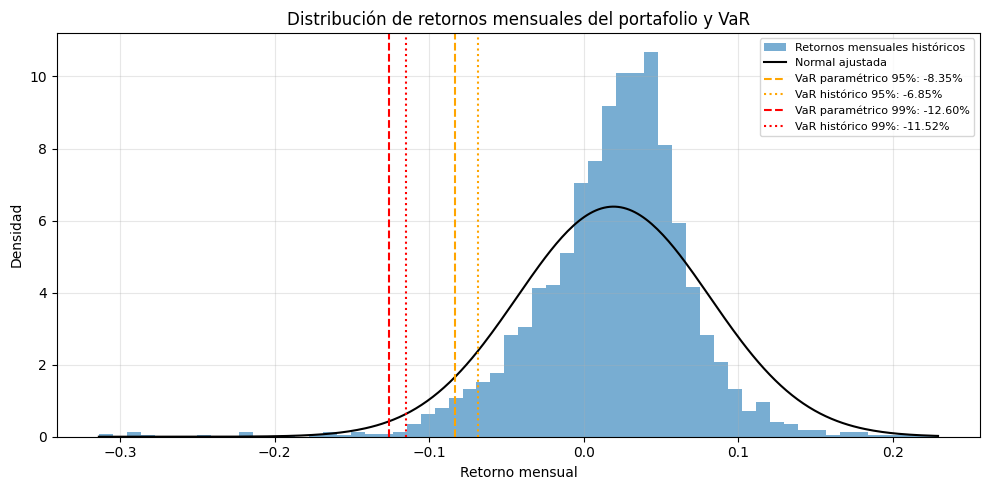

Peor mes histórico del portafolio: -31.38% terminado el 2020-03-23


In [87]:
# 4.3 Gráfica: distribución de retornos mensuales del portafolio y VaR
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(ret_mens_hist, bins=60, density=True, alpha=0.6, label='Retornos mensuales históricos')
x = np.linspace(ret_mens_hist.min(), ret_mens_hist.max(), 300)
ax.plot(x, norm.pdf(x, mu_m, sd_m), 'k-', lw=1.5, label='Normal ajustada')
colores = {'95%': 'orange', '99%': 'red'}
for conf, fila in tabla_var.iterrows():
    ax.axvline(-fila['VaR paramétrico (%)'] / 100, color=colores[conf], ls='--',
               label=f'VaR paramétrico {conf}: -{fila["VaR paramétrico (%)"]:.2f}%')
    ax.axvline(-fila['VaR histórico (%)'] / 100, color=colores[conf], ls=':',
               label=f'VaR histórico {conf}: -{fila["VaR histórico (%)"]:.2f}%')
ax.set_title('Distribución de retornos mensuales del portafolio y VaR')
ax.set_xlabel('Retorno mensual'); ax.set_ylabel('Densidad')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print('Peor mes histórico del portafolio:', f'{ret_mens_hist.min():.2%}',
      'terminado el', ret_mens_hist.idxmin().date())

## 5. Beta de cada acción y del portafolio por CAPM

**Modelo CAPM (forma de regresión, retornos en exceso):**


- Retorno diario del S&P 500 (portafolio de mercado).
- Tasa libre de riesgo diaria = rendimiento del T-Bill a 13 semanas (^IRX) / 252, la tasa de corto plazo coherente con retornos diarios.
-Sensibilidad de la acción frente a los movimientos del mercado.
- El $R^2$ de la regresión indica qué proporción de la varianza de la acción es **riesgo sistemático** (cubrible con futuros sobre el índice).

**Beta del portafolio:** promedio ponderado con los pesos óptimos.

*Nota:* ^GSPC es un índice de precios (sin dividendos), mientras que las acciones usan precios ajustados. Esto afecta levemente el intercepto ($\alpha$), no la beta.

In [88]:
# 5.1 Tasa libre de riesgo diaria histórica (T-Bill 13 semanas)
import statsmodels.api as sm

irx = yf.download('^IRX', start=INICIO, end=FIN, auto_adjust=False, progress=False)['Close']
irx = irx.squeeze().reindex(retornos.index).ffill().bfill()
rf_d = irx / 100 / DIAS_ANO

exc = retornos.sub(rf_d, axis=0)
exc_m = exc[INDICE]
print('Tasa libre de riesgo diaria promedio:', f'{rf_d.mean():.6%}', '| anualizada:', f'{rf_d.mean()*DIAS_ANO:.4%}')

Tasa libre de riesgo diaria promedio: 0.008992% | anualizada: 2.2659%


In [89]:
# 5.2 Regresión CAPM por acción
filas, modelos = [], {}
for t in TICKERS:
    X = sm.add_constant(exc_m)
    m = sm.OLS(exc[t], X).fit()
    modelos[t] = m
    beta_cov = retornos[t].cov(retornos[INDICE]) / retornos[INDICE].var()
    filas.append({
        'Beta (regresión CAPM)': m.params[INDICE],
        'Beta (Cov/Var)':        beta_cov,
        'Error estándar beta':   m.bse[INDICE],
        't-estadístico beta':    m.tvalues[INDICE],
        'Alfa diaria':           m.params['const'],
        'Alfa anualizada (%)':   m.params['const'] * DIAS_ANO * 100,
        'p-valor alfa':          m.pvalues['const'],
        'R² (riesgo sistemático)': m.rsquared,
    })
tabla_beta = pd.DataFrame(filas, index=TICKERS)
tabla_beta.to_csv('betas_capm.csv')
tabla_beta.round(4)

,Beta (regresión CAPM),Beta (Cov/Var),Error estándar beta,t-estadístico beta,Alfa diaria,Alfa anualizada (%),p-valor alfa,R² (riesgo sistemático)
MSFT,1.174400,1.174300,0.018300,64.155100,0.000400,9.678600,0.065500,0.621100
JPM,1.072700,1.072800,0.021300,50.271000,0.000300,7.409900,0.226300,0.501600
KO,0.518900,0.518900,0.017200,30.237300,0.000100,2.010100,0.683200,0.266900


In [90]:
# 5.3 Beta del portafolio y verificación por regresión directa
betas = tabla_beta['Beta (regresión CAPM)']
tabla_bp = pd.DataFrame({'Peso óptimo': W_OPT, 'Beta': betas.values,
                         'Contribución (w x beta)': W_OPT * betas.values}, index=TICKERS)
tabla_bp.loc['Portafolio'] = [W_OPT.sum(), np.nan, tabla_bp['Contribución (w x beta)'].sum()]
BETA_P = tabla_bp.loc['Portafolio', 'Contribución (w x beta)']

#Regresión del portafolio completo contra el mercado
exc_p = (retornos[TICKERS] @ W_OPT) - rf_d
m_p = sm.OLS(exc_p, sm.add_constant(exc_m)).fit()

display(tabla_bp.round(4))
print(f'Beta del portafolio (promedio ponderado): {BETA_P:.4f}')
print(f'Beta del portafolio (regresión directa) : {m_p.params[INDICE]:.4f}')
print(f'R² del portafolio: {m_p.rsquared:.4f}  ->  {m_p.rsquared:.1%} de la varianza es riesgo de mercado')
print(f'Exposición sistemática: beta x capital = USD {BETA_P * CAPITAL:,.0f}')

,Peso óptimo,Beta,Contribución (w x beta)
MSFT,0.567900,1.174400,0.666900
JPM,0.332100,1.072700,0.356300
KO,0.100000,0.518900,0.051900
Portafolio,1.000000,NaN,1.075100


Beta del portafolio (promedio ponderado): 1.0751
Beta del portafolio (regresión directa) : 1.0751
R² del portafolio: 0.8056  ->  80.6% de la varianza es riesgo de mercado
Exposición sistemática: beta x capital = USD 21,501,749


In [91]:
# 5.4 Retorno esperado según CAPM vs retorno histórico
rm_anual = retornos[INDICE].mean() * DIAS_ANO
prima = rm_anual - RF
capm = pd.DataFrame({
    'Beta': list(betas.values) + [BETA_P],
    'Retorno CAPM (%)': [(RF + b * prima) * 100 for b in list(betas.values) + [BETA_P]],
    'Retorno histórico (%)': list(mu.values * 100) + [RET_P * 100],
}, index=TICKERS + ['Portafolio'])
print(f'Retorno de mercado histórico: {rm_anual:.4%} | rf (5 años): {RF:.4%} | prima de mercado: {prima:.4%}')
capm.round(4)

Retorno de mercado histórico: 14.0973% | rf (5 años): 4.0230% | prima de mercado: 10.0743%


,Beta,Retorno CAPM (%),Retorno histórico (%)
MSFT,1.174400,15.854500,25.839600
JPM,1.072700,14.829900,22.367600
KO,0.518900,9.250300,10.414900
Portafolio,1.075100,14.853800,23.143900


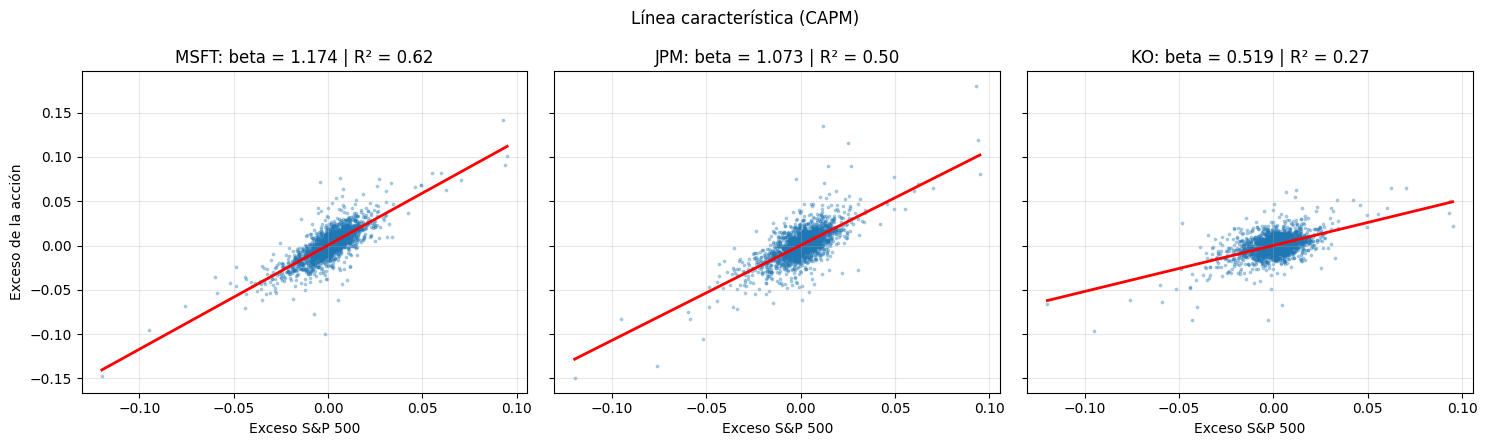

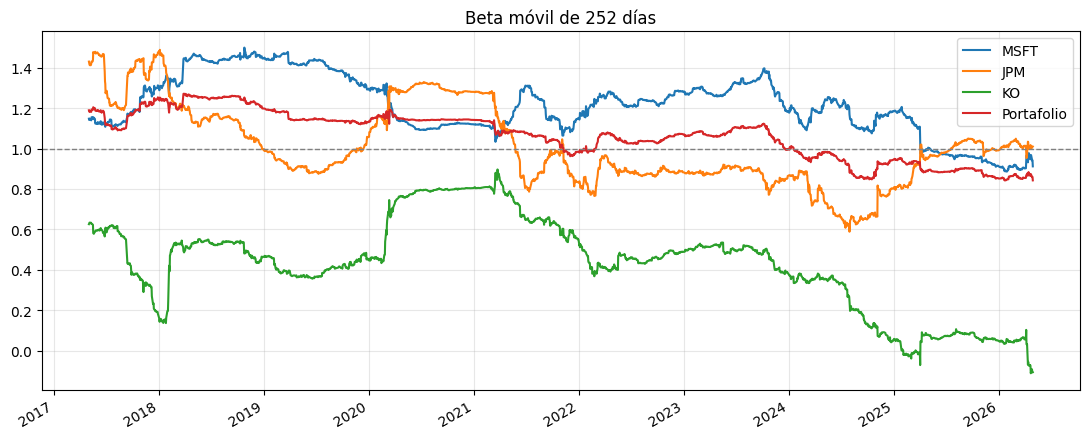

In [92]:
# 5.5 Gráficas: líneas características y beta móvil de 1 año
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, t in zip(axes, TICKERS):
    ax.scatter(exc_m, exc[t], s=3, alpha=0.3)
    xx = np.linspace(exc_m.min(), exc_m.max(), 50)
    ax.plot(xx, modelos[t].params['const'] + modelos[t].params[INDICE] * xx, 'r-', lw=2)
    ax.set_title(f'{t}: beta = {modelos[t].params[INDICE]:.3f} | R² = {modelos[t].rsquared:.2f}')
    ax.set_xlabel('Exceso S&P 500'); ax.grid(alpha=0.3)
axes[0].set_ylabel('Exceso de la acción')
plt.suptitle('Línea característica (CAPM)'); plt.tight_layout(); plt.show()

beta_movil = pd.DataFrame({t: retornos[t].rolling(DIAS_ANO).cov(retornos[INDICE]) / retornos[INDICE].rolling(DIAS_ANO).var()
                           for t in TICKERS}).dropna()
beta_movil['Portafolio'] = beta_movil[TICKERS] @ W_OPT
ax = beta_movil.plot(figsize=(11, 4.5), title='Beta móvil de 252 días')
ax.axhline(1, color='gray', ls='--', lw=1); ax.grid(alpha=0.3); ax.set_xlabel('')
plt.tight_layout(); plt.show()

## Ficha técnica del contrato de futuros: E-mini S&P 500 (CME)

| Característica | Detalle |
|---|---|
| Bolsa | CME Group (Chicago Mercantile Exchange), plataforma CME Globex |
| Código | ES |
| Activo subyacente | Índice S&P 500 |
| Multiplicador / tamaño | USD 50 × nivel del índice |
| Tick mínimo | 0,25 puntos = USD 12,50 por contrato |
| Vencimientos | Trimestrales: marzo (H), junio (M), septiembre (U), diciembre (Z) |
| Último día de negociación | Tercer viernes del mes de vencimiento |
| Liquidación | Financiera (en efectivo), contra la Special Opening Quotation (SOQ) del S&P 500 |
| Mark-to-market | Diario, contra el precio de liquidación de cada sesión |
| Margen inicial / mantenimiento | Ver parámetros abajo (los fija CME Clearing y cambian en el tiempo) |

El precio inicial del futuro se descarga abajo (contrato de junio 2026, ESM26, el más cercano al 30/04/2026).

In [93]:
# Condiciones Contrato futuro
MULT = 50
TICK = 0.25
MARGEN_MANT = 28_813
MARGEN_INI  = MARGEN_MANT * 1.10
print(f'Valor del tick: USD {MULT*TICK:.2f}')
print(f'Margen inicial: USD {MARGEN_INI:,.2f} | Margen de mantenimiento: USD {MARGEN_MANT:,.2f}')

Valor del tick: USD 12.50
Margen inicial: USD 31,694.30 | Margen de mantenimiento: USD 28,813.00


In [94]:
# Precio del Futuro al dia
def ultimo_cierre(ticker):
    try:
        d = yf.download(ticker, start='2026-04-20', end=FIN, auto_adjust=False, progress=False)['Close'].squeeze().dropna()
        return d.loc[:'2026-04-30'].iloc[-1], d.loc[:'2026-04-30'].index[-1].date()
    except Exception as e:
        return np.nan, None

F0_jun, f_jun = ultimo_cierre('ESM26.CME')
F0_cont, f_cont = ultimo_cierre('ES=F')
S0 = precios[INDICE].iloc[-1]

print(f'ESM26 (junio 2026): {F0_jun:,.2f}  ({f_jun})')
print(f'ES=F (continuo)   : {F0_cont:,.2f}  ({f_cont})')
print(f'S&P 500 contado   : {S0:,.2f}')

F0 = F0_jun if pd.notna(F0_jun) else F0_cont
print(f'\nPrecio del futuro usado: {F0:,.2f} | Base (F - S): {F0 - S0:,.2f} puntos')
print(f'Valor nocional de 1 contrato: USD {F0 * MULT:,.2f}')

ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: ESM26.CME"}}}
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['ESM26.CME']: YFTzMissingError('possibly delisted; no timezone found')


ESM26 (junio 2026): nan  (None)
ES=F (continuo)   : 7,243.75  (2026-04-30)
S&P 500 contado   : 7,209.01

Precio del futuro usado: 7,243.75 | Base (F - S): 34.74 puntos
Valor nocional de 1 contrato: USD 362,187.50


## 6. Número óptimo de contratos de futuros



- $\beta_P$: beta del portafolio (pregunta 5); $V_P$: valor del portafolio (USD 20.000.000); $F_0$: precio del futuro al 30/04/2026.
- Como los contratos son discretos, se comparan el redondeo hacia abajo y hacia arriba según la **beta residual** del portafolio cubierto:

Se elige el entero que deja la beta residual más cercana a cero.

In [95]:
# 6.1 N° óptimo de contratos de futuro
V_P = CAPITAL
nocional = F0 * MULT
N_star = BETA_P * V_P / nocional

print(f'Beta del portafolio        : {BETA_P:.4f}')
print(f'Exposición sistemática     : USD {BETA_P * V_P:,.2f}')
print(f'Nocional por contrato      : USD {nocional:,.2f}')
print(f'N* (exacto)                : {N_star:.4f} contratos')

Beta del portafolio        : 1.0751
Exposición sistemática     : USD 21,501,749.30
Nocional por contrato      : USD 362,187.50
N* (exacto)                : 59.3663 contratos


In [96]:
# 6.2 Comparación de redondeos N° de contratos a utilizar
opciones = {'Hacia abajo': int(np.floor(N_star)), 'Hacia arriba': int(np.ceil(N_star))}
filas = []
for nombre, N in opciones.items():
    cubierto = N * nocional
    filas.append({'Redondeo': nombre, 'Contratos': N,
                  'Nocional cubierto (USD)': cubierto,
                  'Exposición sistemática (USD)': BETA_P * V_P,
                  'Diferencia (USD)': cubierto - BETA_P * V_P,
                  '% de la exposición cubierta': cubierto / (BETA_P * V_P) * 100,
                  'Beta residual': BETA_P - cubierto / V_P,
                  'Margen inicial total (USD)': N * MARGEN_INI})
tabla_n = pd.DataFrame(filas).set_index('Redondeo')
N_OPT = opciones[tabla_n['Beta residual'].abs().idxmin()]
tabla_n.to_csv('numero_contratos.csv')
display(tabla_n.round(4))
print(f'Número de contratos elegido: {N_OPT} (beta residual más cercana a cero)')

,Contratos,Nocional cubierto (USD),Exposición sistemática (USD),Diferencia (USD),% de la exposición cubierta,Beta residual,Margen inicial total (USD)
Redondeo,,,,,,,
Hacia abajo,59,"21,369,062.500000","21,501,749.299400","-132,686.799400",99.382900,0.006600,"1,869,963.700000"
Hacia arriba,60,"21,731,250.000000","21,501,749.299400","229,500.700600",101.067400,-0.011500,"1,901,658.000000"


Número de contratos elegido: 59 (beta residual más cercana a cero)


In [97]:
# 6.3 Sensibilidad
escenarios = [-0.20, -0.10, -0.05, 0.05, 0.10, 0.20]
filas = []
for dm in escenarios:
    pnl_port = BETA_P * dm * V_P
    pnl_fut  = -N_OPT * F0 * dm * MULT
    filas.append({'Mov. S&P 500': f'{dm:+.0%}', 'P&G portafolio (USD)': pnl_port,
                  'P&G futuros cortos (USD)': pnl_fut, 'P&G neto (USD)': pnl_port + pnl_fut})
pd.DataFrame(filas).set_index('Mov. S&P 500').round(0)

,P&G portafolio (USD),P&G futuros cortos (USD),P&G neto (USD)
Mov. S&P 500,,,
-20%,"-4,300,350.000000","4,273,812.000000","-26,537.000000"
-10%,"-2,150,175.000000","2,136,906.000000","-13,269.000000"
-5%,"-1,075,087.000000","1,068,453.000000","-6,634.000000"
+5%,"1,075,087.000000","-1,068,453.000000","6,634.000000"
+10%,"2,150,175.000000","-2,136,906.000000","13,269.000000"
+20%,"4,300,350.000000","-4,273,812.000000","26,537.000000"


## 7. Posición en futuros: corta vs. larga

Se comparan tres estrategias ante distintos movimientos del S&P 500:
- **Sin cobertura:** solo el portafolio accionario ($\beta = \beta_P$).
- **Cobertura corta:** portafolio + venta de $N$ futuros ($\beta \approx 0$).
- **Posición larga:** portafolio + compra de $N$ futuros ($\beta \approx 2\beta_P$), para mostrar por qué no es una cobertura para quien ya posee las acciones.

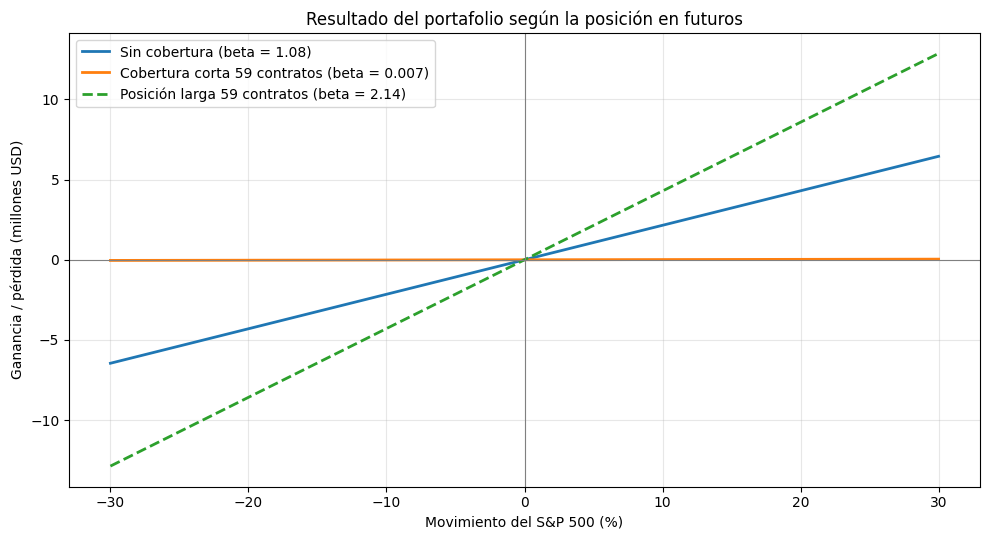

,Sin cobertura (USD),Cobertura corta (USD),Posición larga (USD)
-20%,"-4,300,349.859900","-26,537.359900","-8,574,162.359900"
-10%,"-2,150,174.929900","-13,268.679900","-4,287,081.179900"
+10%,"2,150,174.929900","13,268.679900","4,287,081.179900"
+20%,"4,300,349.859900","26,537.359900","8,574,162.359900"
Beta resultante,1.075100,0.006600,2.143500


In [98]:
# 7.1 Resultado de las tres estrategias según el movimiento del mercado
movs = np.linspace(-0.30, 0.30, 61)
pnl_sin   = BETA_P * movs * V_P
pnl_fut   = N_OPT * F0 * movs * MULT
pnl_corta = pnl_sin - pnl_fut
pnl_larga = pnl_sin + pnl_fut

beta_corta = BETA_P - N_OPT * F0 * MULT / V_P
beta_larga = BETA_P + N_OPT * F0 * MULT / V_P

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(movs * 100, pnl_sin / 1e6,   label=f'Sin cobertura (beta = {BETA_P:.2f})', lw=2)
ax.plot(movs * 100, pnl_corta / 1e6, label=f'Cobertura corta {N_OPT} contratos (beta = {beta_corta:.3f})', lw=2)
ax.plot(movs * 100, pnl_larga / 1e6, label=f'Posición larga {N_OPT} contratos (beta = {beta_larga:.2f})', lw=2, ls='--')
ax.axhline(0, color='gray', lw=0.8); ax.axvline(0, color='gray', lw=0.8)
ax.set_xlabel('Movimiento del S&P 500 (%)'); ax.set_ylabel('Ganancia / pérdida (millones USD)')
ax.set_title('Resultado del portafolio según la posición en futuros'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

tabla7 = pd.DataFrame({
    'Sin cobertura (USD)': BETA_P * np.array([-0.2, -0.1, 0.1, 0.2]) * V_P,
}, index=['-20%', '-10%', '+10%', '+20%'])
d = np.array([-0.2, -0.1, 0.1, 0.2])
tabla7['Cobertura corta (USD)'] = tabla7['Sin cobertura (USD)'] - N_OPT * F0 * d * MULT
tabla7['Posición larga (USD)']  = tabla7['Sin cobertura (USD)'] + N_OPT * F0 * d * MULT
tabla7.loc['Beta resultante'] = [BETA_P, beta_corta, beta_larga]
tabla7.round(4)

## 8. Flujos de la posición en futuros y llamados al margen

**Datos:** precios reales del futuro E-mini S&P 500 (ES=F) desde el 30/04/2026 hasta la fecha más reciente disponible.

**Supuestos:**
- Posición: **59 contratos** (pregunta 6). Se evalúan la posición corta (cobertura) y, como contraste, la larga.
- **Liquidación mensual:** el saldo de la cuenta de margen se revisa al cierre de cada mes. Si cae por debajo del **margen de mantenimiento** ($N \times$ MM), hay **llamado al margen** y se repone hasta el **margen inicial** ($N \times$ MI). Los excedentes no se retiran.
- **Vencimientos:** el contrato vence el tercer viernes de junio, septiembre y diciembre. En el mes de vencimiento la posición se divide en dos tramos: (1) el contrato que vence se liquida contra la *Special Opening Quotation*, aproximada con el precio de **apertura del S&P 500** del día de vencimiento; (2) se abre el siguiente contrato al cierre de ES=F ese mismo día.

- Como contraste, se simula también la **liquidación diaria** (mark-to-market real), excluyendo el salto de precio que produce el cambio de contrato en la serie continua.

In [99]:
# 8.1 Datos del futuro y del índice desde el inicio
HOY = pd.Timestamp.today().normalize() + pd.Timedelta(days=1)
dat = yf.download(['ES=F', '^GSPC'], start='2026-04-30', end=HOY, auto_adjust=False, progress=False)
es        = dat['Close']['ES=F'].dropna()
spx_close = dat['Close']['^GSPC'].dropna()
spx_open  = dat['Open']['^GSPC'].dropna()
comunes = es.index.intersection(spx_close.index)
es, spx_close = es.loc[comunes], spx_close.loc[comunes]
print('Datos del futuro desde', es.index[0].date(), 'hasta', es.index[-1].date(), '|', len(es), 'sesiones')

# Vencimientos trimestrales (tercer viernes)
def tercer_viernes(y, m):
    d = pd.Timestamp(y, m, 1)
    return d + pd.Timedelta(days=(4 - d.weekday()) % 7) + pd.Timedelta(weeks=2)

# Si el tercer viernes es festivo
from pandas.tseries.holiday import USFederalHolidayCalendar
FESTIVOS = USFederalHolidayCalendar().holidays('2026-01-01', '2030-12-31')
def dia_habil_anterior(d):
    while d in FESTIVOS or d.weekday() >= 5:
        d -= pd.Timedelta(days=1)
    return d

COD_MES = {3: 'H', 6: 'M', 9: 'U', 12: 'Z'}
VENC = [(dia_habil_anterior(tercer_viernes(y, m)), f'ES{COD_MES[m]}{str(y)[2:]}')
        for y in range(2026, 2031) for m in (3, 6, 9, 12)
        if pd.Timestamp('2026-04-30') < tercer_viernes(y, m) <= pd.Timestamp('2030-06-30')]
VENC = pd.DataFrame(VENC, columns=['Vencimiento', 'Contrato'])

def contrato_vigente(fecha):
    fila = VENC[VENC['Vencimiento'] > fecha].iloc[0]
    return fila['Contrato'], fila['Vencimiento']

print('Último dato disponible:', es.index[-1].date(), '(si es hoy, puede ser un precio intradía)')
VENC.head(6)

Datos del futuro desde 2026-04-30 hasta 2026-10-28 | 126 sesiones
Último dato disponible: 2026-10-28 (si es hoy, puede ser un precio intradía)


,Vencimiento,Contrato
0,2026-06-18,ESM26
1,2026-09-18,ESU26
2,2026-12-18,ESZ26
3,2027-03-19,ESH27
4,2027-06-17,ESM27
5,2027-09-17,ESU27


In [100]:
# 8.2 Liquidación MENSUAL de la cuenta de margen
N = N_OPT
MARGEN_INI_TOT, MARGEN_MANT_TOT = N * MARGEN_INI, N * MARGEN_MANT

fin_mes = es.groupby(es.index.to_period('M')).apply(lambda s: s.index[-1])
fin_mes = [d for d in fin_mes if d >= pd.Timestamp('2026-04-30')]

filas, saldo = [], MARGEN_INI_TOT
for ini, fin in zip(fin_mes[:-1], fin_mes[1:]):
    cod, venc = contrato_vigente(ini)
    tramos = []
    if ini < venc <= fin and venc in spx_open.index:          # mes con vencimiento -> dos tramos
        tramos.append((cod, es[ini], spx_open[venc], ini, venc, 'Vence (liquidación SOQ)'))
        cod2, _ = contrato_vigente(venc)
        tramos.append((cod2, es[venc], es[fin], venc, fin, 'Nuevo contrato'))
    else:
        tramos.append((cod, es[ini], es[fin], ini, fin, ''))

    for k, (c, p0, p1, d0, d1, nota) in enumerate(tramos):
        var = p1 - p0
        gp_larga = var * MULT * N
        gp_corta = -gp_larga
        saldo += gp_corta
        ultimo = (k == len(tramos) - 1)
        llamado = ultimo and (saldo < MARGEN_MANT_TOT)
        repos = (MARGEN_INI_TOT - saldo) if llamado else 0.0
        parcial = (fin == es.index[-1]) and (fin < (fin + pd.offsets.BMonthEnd(0)))
        fila = {'Mes': fin.strftime('%Y-%m') + (' (parcial)' if parcial else ''),
                'Contrato': c, 'Desde': d0.date(), 'Hasta': d1.date(), 'Nota': nota,
                'Precio inicial': p0, 'Precio final': p1, 'Variación (pts)': var,
                'G/P larga (USD)': gp_larga, 'G/P corta (USD)': gp_corta,
                'Saldo antes de llamado (USD)': saldo,
                'Llamado al margen': ('Sí' if llamado else 'No') if ultimo else '—',
                'Reposición (USD)': repos}
        saldo += repos
        fila['Saldo final (USD)'] = saldo
        filas.append(fila)

flujos = pd.DataFrame(filas)
flujos.to_csv('flujos_margen_mensual.csv', index=False)
print(f'Margen inicial total: USD {MARGEN_INI_TOT:,.2f} | Margen de mantenimiento total: USD {MARGEN_MANT_TOT:,.2f}')
flujos.round(2)

Margen inicial total: USD 1,869,963.70 | Margen de mantenimiento total: USD 1,699,967.00


,Mes,Contrato,Desde,Hasta,Nota,Precio inicial,Precio final,Variación (pts),G/P larga (USD),G/P corta (USD),Saldo antes de llamado (USD),Llamado al margen,Reposición (USD),Saldo final (USD)
0,2026-05,ESM26,2026-04-30,2026-05-29,,"7,243.750000","7,595.750000",352.000000,"1,038,400.000000","-1,038,400.000000","831,563.700000",Sí,"1,038,400.000000","1,869,963.700000"
1,2026-06,ESM26,2026-05-29,2026-06-18,Vence (liquidación SOQ),"7,595.750000","7,487.360000",-108.390000,"-319,750.900000","319,750.900000","2,189,714.600000",—,0.000000,"2,189,714.600000"
2,2026-06,ESU26,2026-06-18,2026-06-30,Nuevo contrato,"7,508.430000","7,548.250000",39.820000,"117,468.480000","-117,468.480000","2,072,246.120000",No,0.000000,"2,072,246.120000"
3,2026-07,ESU26,2026-06-30,2026-07-31,,"7,548.250000","7,519.250000",-29.000000,"-85,550.000000","85,550.000000","2,157,796.120000",No,0.000000,"2,157,796.120000"
4,2026-08,ESU26,2026-07-31,2026-08-31,,"7,519.250000","7,699.000000",179.750000,"530,262.500000","-530,262.500000","1,627,533.620000",Sí,"242,430.080000","1,869,963.700000"
5,2026-09,ESU26,2026-08-31,2026-09-18,Vence (liquidación SOQ),"7,699.000000","7,657.170000",-41.830000,"-123,398.730000","123,398.730000","1,993,362.430000",—,0.000000,"1,993,362.430000"
6,2026-09,ESZ26,2026-09-18,2026-09-30,Nuevo contrato,"7,657.350000","7,715.500000",58.150000,"171,542.210000","-171,542.210000","1,821,820.220000",No,0.000000,"1,821,820.220000"
7,2026-10 (parcial),ESZ26,2026-09-30,2026-10-28,,"7,715.500000","7,756.000000",40.500000,"119,475.000000","-119,475.000000","1,702,345.220000",No,0.000000,"1,702,345.220000"


In [101]:
# 8.3 Resumen por contrato (trimestre) y total
resumen_trim = flujos.groupby('Contrato', sort=False).agg(
    Desde=('Desde', 'first'), Hasta=('Hasta', 'last'),
    Var_pts=('Variación (pts)', 'sum'),
    GP_larga=('G/P larga (USD)', 'sum'), GP_corta=('G/P corta (USD)', 'sum'),
    Reposiciones=('Reposición (USD)', 'sum'))
resumen_trim.loc['Total'] = ['', '', resumen_trim['Var_pts'].sum(), resumen_trim['GP_larga'].sum(),
                             resumen_trim['GP_corta'].sum(), resumen_trim['Reposiciones'].sum()]
display(resumen_trim.round(2))

n_llamados_m = (flujos['Llamado al margen'] == 'Sí').sum()
print(f'Llamados al margen (liquidación mensual): {n_llamados_m} | Reposición total: USD {flujos["Reposición (USD)"].sum():,.2f}')
print(f'Saldo final de la cuenta de margen: USD {flujos["Saldo final (USD)"].iloc[-1]:,.2f}')

,Desde,Hasta,Var_pts,GP_larga,GP_corta,Reposiciones
Contrato,,,,,,
ESM26,2026-04-30,2026-06-18,243.610000,"718,649.100000","-718,649.100000","1,038,400.000000"
ESU26,2026-06-18,2026-09-18,148.740000,"438,782.250000","-438,782.250000","242,430.080000"
ESZ26,2026-09-18,2026-10-28,98.650000,"291,017.210000","-291,017.210000",0.000000
Total,,,491.000000,"1,448,448.560000","-1,448,448.560000","1,280,830.080000"


Llamados al margen (liquidación mensual): 2 | Reposición total: USD 1,280,830.08
Saldo final de la cuenta de margen: USD 1,702,345.22


In [102]:
# 8.4 Contraste: liquidación DIARIA
d_es = es.diff()
d_spot_escalado = spx_close.diff() * es.shift() / spx_close.shift()
# Excluir el salto por cambio de contrato en la serie continua ES=F
for v in VENC['Vencimiento']:
    ventana = es.index[(es.index > v - pd.Timedelta(days=14)) & (es.index <= v + pd.Timedelta(days=3))]
    if len(ventana) == 0: continue
    brecha = (d_es - d_spot_escalado).loc[ventana].abs()
    if brecha.max() > 15:                      # salto mayor a 15 puntos = cambio de contrato
        d_es.loc[brecha.idxmax()] = d_spot_escalado.loc[brecha.idxmax()]

saldo_d, filas_d = MARGEN_INI_TOT, []
for fecha, dp in d_es.dropna().items():
    saldo_d += -dp * MULT * N
    llamado = saldo_d < MARGEN_MANT_TOT
    repos = MARGEN_INI_TOT - saldo_d if llamado else 0.0
    filas_d.append({'Fecha': fecha, 'Saldo antes (USD)': saldo_d, 'Llamado': llamado, 'Reposición (USD)': repos})
    saldo_d += repos
diario = pd.DataFrame(filas_d).set_index('Fecha')
diario['Saldo final (USD)'] = diario['Saldo antes (USD)'] + diario['Reposición (USD)']

comp = pd.DataFrame({
    'Liquidación mensual': [n_llamados_m, flujos['Reposición (USD)'].sum()],
    'Liquidación diaria':  [int(diario['Llamado'].sum()), diario['Reposición (USD)'].sum()],
}, index=['Número de llamados al margen', 'Reposición total (USD)'])
display(comp.round(2))
print('Fechas de llamados (diaria):', [d.date() for d in diario.index[diario['Llamado']]])

,Liquidación mensual,Liquidación diaria
Número de llamados al margen,2.000000,5.000000
Reposición total (USD),"1,280,830.080000","1,539,162.500000"


Fechas de llamados (diaria): [datetime.date(2026, 5, 6), datetime.date(2026, 5, 13), datetime.date(2026, 5, 26), datetime.date(2026, 5, 29), datetime.date(2026, 8, 4)]


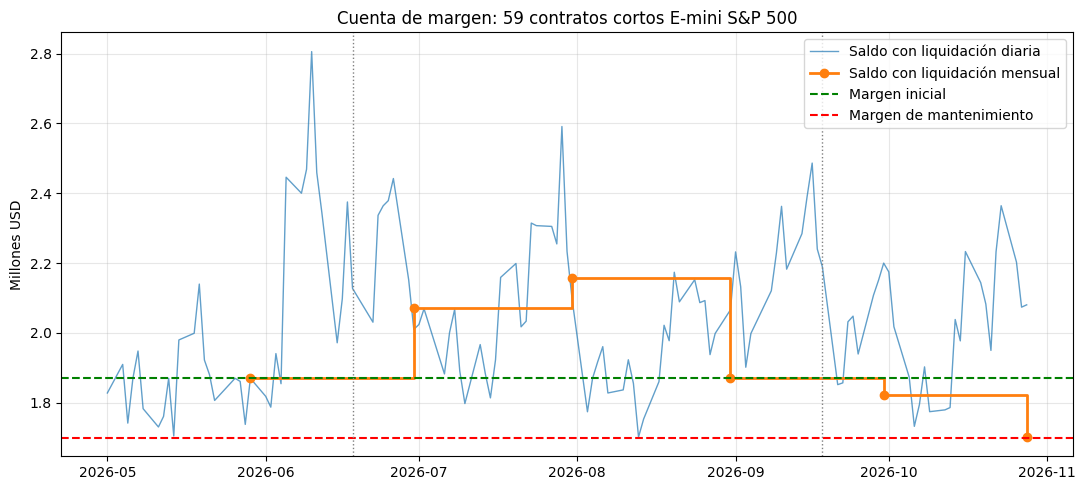

In [103]:
# 8.5 Gráfica de la cuenta de margen
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(diario.index, diario['Saldo final (USD)'] / 1e6, lw=1, alpha=0.7, label='Saldo con liquidación diaria')
fm = pd.to_datetime(flujos.groupby('Mes')['Hasta'].last())
ax.step(fm, flujos.groupby('Mes')['Saldo final (USD)'].last() / 1e6, where='post', lw=2, marker='o',
        label='Saldo con liquidación mensual')
ax.axhline(MARGEN_INI_TOT / 1e6, color='green', ls='--', label='Margen inicial')
ax.axhline(MARGEN_MANT_TOT / 1e6, color='red', ls='--', label='Margen de mantenimiento')
for v in VENC['Vencimiento']:
    if es.index[0] < v < es.index[-1]: ax.axvline(v, color='gray', ls=':', lw=1)
ax.set_title(f'Cuenta de margen: {N} contratos cortos E-mini S&P 500')
ax.set_ylabel('Millones USD'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 9. Roll-over trimestral, riesgo de base y estrategias siempre corta / siempre larga

El análisis tiene dos partes:

**A. Ex post (datos reales, 30/04/2026 – fecha actual):** se evalúan los dos roll-overs ya ocurridos (18/06 y 18/09) y el contrato de diciembre abierto: cierre de cada contrato, apertura del siguiente, G/P realizada, base, y el efecto sobre el valor del portafolio cubierto frente al no cubierto.

**B. Ex ante (simulación Monte Carlo, horizonte completo hasta el 30/04/2030):** los trimestres restantes aún no han ocurrido, por lo que se proyectan con 10.000 escenarios.
- Índice: movimiento browniano geométrico con el retorno (14,10%) y la volatilidad (18,07%) históricos del S&P 500.
- Portafolio: CAPM con la beta (1,0751) y el riesgo específico (residuo de la regresión.
- Precio del futuro por **costo de mantener**:rendimiento por dividendos del S&P 500 (1,24%).
- En cada vencimiento se cierra el contrato ($F_T = S_T$, la base converge a cero) y se abre el siguiente , recalculado con el valor del portafolio en ese momento.
- El 30/04/2030 la última posición se cierra **antes** de su vencimiento, con base distinta de cero.





In [104]:
# 9.1 Valor real del portafolio desde el 30/04/2026
acc_post = yf.download(TICKERS, start='2026-04-30', end=HOY, auto_adjust=True, progress=False)['Close'][TICKERS].dropna()
acc_post = acc_post.loc[acc_post.index.intersection(es.index)]
acciones_n = W_OPT * CAPITAL / acc_post.iloc[0].values
V_real = (acc_post * acciones_n).sum(axis=1)

# G/P acumulada de los futuros cortos
gp_fut_acum = flujos.set_index(pd.to_datetime(flujos['Hasta']))['G/P corta (USD)'].cumsum()

fechas_clave = [pd.Timestamp('2026-04-30')] + list(VENC['Vencimiento'][VENC['Vencimiento'] < es.index[-1]]) + [es.index[-1]]
filas = []
for f in fechas_clave:
    v = V_real.loc[:f].iloc[-1]
    gp = gp_fut_acum.loc[:f].iloc[-1] if f > pd.Timestamp('2026-04-30') else 0.0
    filas.append({'Fecha': f.date(), 'S&P 500': spx_close.loc[:f].iloc[-1], 'Valor portafolio sin cobertura (USD)': v,
                  'G/P acumulada futuros cortos (USD)': gp, 'Valor portafolio cubierto (USD)': v + gp,
                  'Valor portafolio + futuros largos (USD)': v - gp})
valores_real = pd.DataFrame(filas).set_index('Fecha')
valores_real['Rent. sin cobertura (%)'] = (valores_real['Valor portafolio sin cobertura (USD)'] / CAPITAL - 1) * 100
valores_real['Rent. cubierto (%)']      = (valores_real['Valor portafolio cubierto (USD)'] / CAPITAL - 1) * 100
valores_real['Rent. siempre largo (%)'] = (valores_real['Valor portafolio + futuros largos (USD)'] / CAPITAL - 1) * 100
valores_real['Rent. S&P 500 (%)']       = (valores_real['S&P 500'] / spx_close.iloc[0] - 1) * 100
valores_real.to_csv('valores_reales_cobertura.csv')
valores_real.round(2)

,S&P 500,Valor portafolio sin cobertura (USD),G/P acumulada futuros cortos (USD),Valor portafolio cubierto (USD),Valor portafolio + futuros largos (USD),Rent. sin cobertura (%),Rent. cubierto (%),Rent. siempre largo (%),Rent. S&P 500 (%)
Fecha,,,,,,,,,
2026-04-30,"7,209.010000","20,000,000.000000",0.000000,"20,000,000.000000","20,000,000.000000",0.000000,0.000000,0.000000,0.000000
2026-06-18,"7,500.580000","19,515,765.250000","-718,649.100000","18,797,116.160000","20,234,414.350000",-2.420000,-6.010000,1.170000,4.040000
2026-09-18,"7,650.500000","23,526,052.440000","-1,157,431.350000","22,368,621.090000","24,683,483.780000",17.630000,11.840000,23.420000,6.120000
2026-10-28,"7,743.980000","24,391,429.140000","-1,448,448.560000","22,942,980.580000","25,839,877.700000",21.960000,14.710000,29.200000,7.420000


In [105]:
# 9.2 Roll-overs reales: cierre, apertura, G/P realizada y descomposición por base
filas = []
for _, (venc, cod) in VENC.iterrows():
    tramo_ini = flujos[(flujos['Contrato'] == cod)].iloc[0]
    tramo_fin = flujos[(flujos['Contrato'] == cod)].iloc[-1] if (flujos['Contrato'] == cod).any() else None
    if tramo_fin is None: break
    d0 = pd.Timestamp(tramo_ini['Desde'])
    F_ap = tramo_ini['Precio inicial']
    S_ap = spx_close.loc[:d0].iloc[-1]
    cerrado = venc <= es.index[-1]
    d1 = venc if cerrado else es.index[-1]
    F_ci = spx_open[venc] if cerrado else es.iloc[-1]
    S_ci = spx_open[venc] if cerrado else spx_close.iloc[-1]
    base_ap, base_ci = F_ap - S_ap, F_ci - S_ci
    gp = -(F_ci - F_ap) * MULT * N
    filas.append({'Contrato': cod, 'Apertura': d0.date(), 'Cierre': d1.date(),
                  'Estado': 'Liquidado al vencimiento' if cerrado else 'Abierto (valorado hoy)',
                  'F apertura': F_ap, 'S apertura': S_ap, 'Base apertura (F-S)': base_ap,
                  'F cierre': F_ci, 'S cierre': S_ci, 'Base cierre (F-S)': base_ci,
                  'G/P realizada corta (USD)': gp,
                  'Por movimiento del índice (USD)': -(S_ci - S_ap) * MULT * N,
                  'Por cambio de base (USD)': (base_ap - base_ci) * MULT * N,
                  'N recomendado al abrir': BETA_P * V_real.loc[:d0].iloc[-1] / (F_ap * MULT)})
    if not cerrado: break
rolls_real = pd.DataFrame(filas).set_index('Contrato')

# Brecha de roll: diferencia entre la liquidación del contrato que vence y la apertura del siguiente
rolls_real['Brecha de roll (pts)'] = rolls_real['F apertura'] - rolls_real['F cierre'].shift(1)
rolls_real.to_csv('rolls_reales.csv')
rolls_real.round(2).T

Contrato,ESM26,ESU26,ESZ26
Apertura,2026-04-30,2026-06-18,2026-09-18
Cierre,2026-06-18,2026-09-18,2026-10-28
Estado,Liquidado al vencimiento,Liquidado al vencimiento,Abierto (valorado hoy)
F apertura,"7,243.750000","7,508.430000","7,657.350000"
S apertura,"7,209.010000","7,500.580000","7,650.500000"
Base apertura (F-S),34.740000,7.850000,6.850000
F cierre,"7,487.360000","7,657.170000","7,756.000000"
S cierre,"7,487.360000","7,657.170000","7,743.980000"
Base cierre (F-S),0.000000,0.000000,12.020000
G/P realizada corta (USD),"-718,649.100000","-438,782.250000","-291,017.210000"


In [106]:
# 9.3 Efectividad real de la cobertura (datos diarios desde el 30/04/2026)
dV = V_real.diff().dropna()
dF = d_es.reindex(dV.index).fillna(0)
pnl_cubierto = dV - N * MULT * dF

r_sin = dV / V_real.shift().dropna()
r_cub = pnl_cubierto / V_real.shift().dropna()
r_fut = dF / es.shift().reindex(dV.index)
beta_real = np.cov(r_sin, r_fut)[0, 1] / np.var(r_fut, ddof=1)
corr_real = np.corrcoef(r_sin, r_fut)[0, 1]

efect = pd.Series({
    'Volatilidad anualizada sin cobertura (%)': r_sin.std() * np.sqrt(DIAS_ANO) * 100,
    'Volatilidad anualizada cubierto (%)':      r_cub.std() * np.sqrt(DIAS_ANO) * 100,
    'Reducción de varianza (efectividad, %)':   (1 - r_cub.var() / r_sin.var()) * 100,
    'Beta realizada vs futuro':                 beta_real,
    'Correlación realizada portafolio-futuro':  corr_real,
})
efect.round(4)

,0
Volatilidad anualizada sin cobertura (%),21.234000
Volatilidad anualizada cubierto (%),19.921700
"Reducción de varianza (efectividad, %)",11.978800
Beta realizada vs futuro,0.729500
Correlación realizada portafolio-futuro,0.407800


In [107]:
# 9.3b Robustez: correlación diaria vs. semanal, frente al futuro y al índice de contado
r_spx = spx_close.pct_change().reindex(r_sin.index)
sem = lambda s: (1 + s).resample('W-FRI').prod() - 1
rob = pd.DataFrame({
    'Diaria': [np.corrcoef(r_sin, r_fut)[0, 1], np.corrcoef(r_sin, r_spx)[0, 1], np.corrcoef(r_fut, r_spx)[0, 1]],
    'Semanal': [sem(r_sin).corr(sem(r_fut)), sem(r_sin).corr(sem(r_spx)), sem(r_fut).corr(sem(r_spx))],
}, index=['Portafolio vs futuro', 'Portafolio vs S&P 500 contado', 'Futuro vs S&P 500 contado'])
display(rob.round(4))
print('Los 5 días de mayor variación del portafolio:')
print(r_sin.loc[r_sin.abs().sort_values(ascending=False).head(5).index].round(4))

,Diaria,Semanal
Portafolio vs futuro,0.407800,0.439900
Portafolio vs S&P 500 contado,0.422400,0.437500
Futuro vs S&P 500 contado,0.992700,0.996400


Los 5 días de mayor variación del portafolio:
Date
2026-07-30   0.088000
2026-05-29   0.033000
2026-08-03   0.028200
2026-06-26   0.025800
2026-09-25   0.025600
dtype: float64


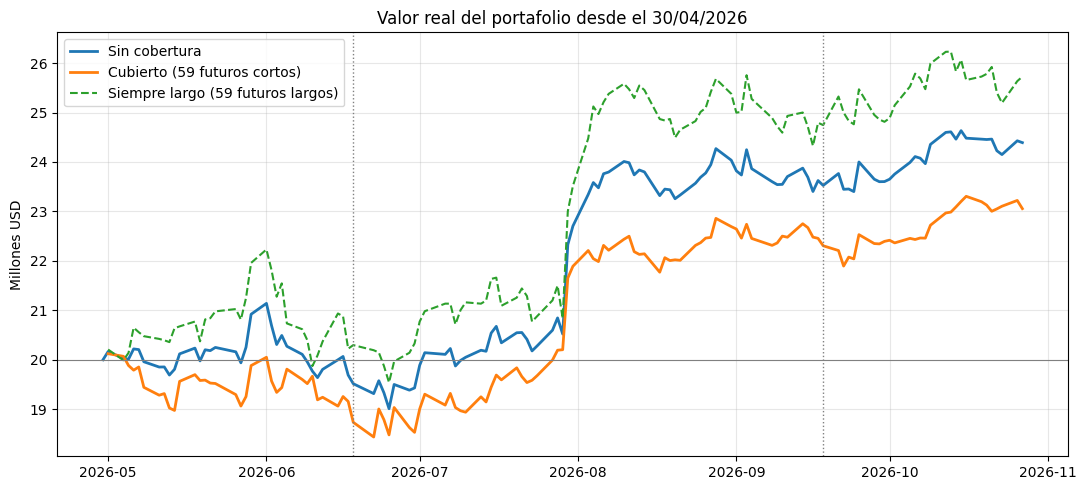

In [108]:
# 9.4 Gráfica real: portafolio sin cobertura vs cubierto vs siempre largo
gp_diario = (-N * MULT * dF).cumsum()
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(V_real.index, V_real / 1e6, label='Sin cobertura', lw=2)
ax.plot(gp_diario.index, (V_real.loc[gp_diario.index] + gp_diario) / 1e6, label=f'Cubierto ({N} futuros cortos)', lw=2)
ax.plot(gp_diario.index, (V_real.loc[gp_diario.index] - gp_diario) / 1e6, label=f'Siempre largo ({N} futuros largos)', lw=1.5, ls='--')
ax.axhline(CAPITAL / 1e6, color='gray', lw=0.8)
for v in VENC['Vencimiento']:
    if es.index[0] < v < es.index[-1]: ax.axvline(v, color='gray', ls=':', lw=1)
ax.set_title('Valor real del portafolio desde el 30/04/2026'); ax.set_ylabel('Millones USD')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [109]:
# 9.5 Parámetros de la simulación
N_SIM   = 10_000
rng     = np.random.default_rng(2026)
R_CARRY = tasas_inicio['^IRX'] / 100
Q_DIV   = 0.0124
MU_M    = retornos[INDICE].mean() * DIAS_ANO
SIG_M   = retornos[INDICE].std() * np.sqrt(DIAS_ANO)
SIG_E   = m_p.resid.std() * np.sqrt(DIAS_ANO)
MU_P    = RF + BETA_P * (MU_M + Q_DIV - RF)
FECHA_FIN = pd.Timestamp('2030-04-30')

# Calendario de períodos: inicio -> vencimientos -> fin del horizonte
venc_h = list(VENC['Vencimiento'][VENC['Vencimiento'] <= FECHA_FIN])
cods_h = list(VENC['Contrato'][VENC['Vencimiento'] <= FECHA_FIN])
sig_cod = VENC[VENC['Vencimiento'] > FECHA_FIN].iloc[0]
puntos = [pd.Timestamp('2026-04-30')] + venc_h + [FECHA_FIN]
contratos = cods_h + [sig_cod['Contrato']]
venc_contr = venc_h + [sig_cod['Vencimiento']]

print(f'r (T-Bill) = {R_CARRY:.4%} | q = {Q_DIV:.2%} | mu índice = {MU_M:.4%} | sigma índice = {SIG_M:.4%}')
print(f'Retorno esperado portafolio (CAPM) = {MU_P:.4%} | riesgo específico anual = {SIG_E:.4%}')
print(f'Número de contratos (roll-overs) en el horizonte: {len(contratos)}')

r (T-Bill) = 3.5850% | q = 1.24% | mu índice = 14.0973% | sigma índice = 18.0653%
Retorno esperado portafolio (CAPM) = 16.1869% | riesgo específico anual = 9.5417%
Número de contratos (roll-overs) en el horizonte: 17


In [110]:
# 9.6 Simulación de los roll-overs trimestrales
S = np.full(N_SIM, float(spx_close.iloc[0]))
V = np.full(N_SIM, float(CAPITAL))
caja_corta = np.zeros(N_SIM); caja_larga = np.zeros(N_SIM)
filas = []
for k, (t0, t1) in enumerate(zip(puntos[:-1], puntos[1:])):
    dt = (t1 - t0).days / 365.25
    tau0 = (venc_contr[k] - t0).days / 365.0
    tau1 = (venc_contr[k] - t1).days / 365.0
    F0_k = S * np.exp((R_CARRY - Q_DIV) * tau0)
    N_k = np.rint(BETA_P * V / (F0_k * MULT))

    z1, z2 = rng.standard_normal(N_SIM), rng.standard_normal(N_SIM)
    R_m = np.exp((MU_M - 0.5 * SIG_M**2) * dt + SIG_M * np.sqrt(dt) * z1) - 1
    R_p = RF * dt + BETA_P * (R_m + Q_DIV * dt - RF * dt) + SIG_E * np.sqrt(dt) * z2
    S1 = S * (1 + R_m)
    F1_k = S1 * np.exp((R_CARRY - Q_DIV) * tau1)
    gp = -(F1_k - F0_k) * MULT * N_k

    filas.append({'Contrato': contratos[k], 'Apertura': t0.date(), 'Cierre': t1.date(),
                  'Días': (t1 - t0).days, 'N promedio': N_k.mean(),
                  'F apertura (prom.)': F0_k.mean(), 'Base apertura (prom., pts)': (F0_k - S).mean(),
                  'Base cierre (prom., pts)': (F1_k - S1).mean(),
                  'G/P corta promedio (USD)': gp.mean(), 'G/P corta P5 (USD)': np.percentile(gp, 5),
                  'G/P corta P95 (USD)': np.percentile(gp, 95),
                  'Rendimiento del roll promedio (USD)': (N_k * MULT * ((F0_k - S) - (F1_k - S1))).mean()})
    V = V * (1 + R_p); S = S1
    caja_corta += gp; caja_larga -= gp

rolls_sim = pd.DataFrame(filas).set_index('Contrato')
rolls_sim.to_csv('rolls_simulados.csv')
rolls_sim.round(2)

,Apertura,Cierre,Días,N promedio,F apertura (prom.),"Base apertura (prom., pts)","Base cierre (prom., pts)",G/P corta promedio (USD),G/P corta P5 (USD),G/P corta P95 (USD),Rendimiento del roll promedio (USD)
Contrato,,,,,,,,,,,
ESM26,2026-04-30,2026-06-18,49,59.000000,"7,231.740000",22.730000,0.000000,"-336,501.810000","-2,772,345.070000","1,971,757.960000","67,054.430000"
ESU26,2026-06-18,2026-09-18,92,59.450000,"7,389.360000",43.550000,0.000000,"-655,889.580000","-4,237,428.460000","2,508,370.390000","129,494.300000"
ESZ26,2026-09-18,2026-12-18,91,59.740000,"7,654.590000",44.620000,0.000000,"-658,946.370000","-4,353,657.300000","2,689,458.510000","133,405.410000"
ESH27,2026-12-18,2027-03-19,91,60.010000,"7,921.640000",46.180000,0.000000,"-731,992.000000","-4,562,765.630000","2,754,188.200000","138,731.440000"
ESM27,2027-03-19,2027-06-17,90,60.270000,"8,213.450000",47.350000,0.000000,"-699,807.870000","-4,646,351.810000","2,892,354.190000","142,934.340000"
ESU27,2027-06-17,2027-09-17,92,60.530000,"8,496.200000",50.070000,0.000000,"-773,126.860000","-5,011,542.440000","2,952,385.840000","151,873.850000"
ESZ27,2027-09-17,2027-12-17,91,60.860000,"8,802.530000",51.310000,0.000000,"-830,944.170000","-5,397,921.670000","3,082,744.330000","156,551.330000"
ESH28,2027-12-17,2028-03-17,91,61.120000,"9,127.790000",53.210000,0.000000,"-791,171.470000","-5,418,334.710000","3,306,232.530000","163,147.130000"
ESM28,2028-03-17,2028-06-16,91,61.440000,"9,441.380000",55.040000,0.000000,"-838,050.120000","-5,677,644.580000","3,372,283.000000","169,731.420000"


In [111]:
# 9.7 Resultado a 4 años: sin cobertura, siempre corto (cubierto) y siempre largo
anios_h = (FECHA_FIN - pd.Timestamp('2026-04-30')).days / 365.25
finales = {'Sin cobertura': V, 'Siempre corto (cubierto)': V + caja_corta, 'Siempre largo': V + caja_larga}
filas = []
for nombre, W in finales.items():
    rt = W / CAPITAL - 1
    ra = np.sign(1 + rt) * np.abs(1 + rt) ** (1 / anios_h) - 1
    filas.append({'Estrategia': nombre, 'Valor final promedio (USD)': W.mean(),
                  'Rent. total promedio (%)': rt.mean() * 100, 'Rent. anual promedio (%)': np.nanmean(ra) * 100,
                  'Desv. rent. total (%)': rt.std() * 100,
                  'Percentil 5 valor final (USD)': np.percentile(W, 5),
                  'Percentil 95 valor final (USD)': np.percentile(W, 95),
                  'Prob. de pérdida (%)': (W < CAPITAL).mean() * 100})
resultado_h = pd.DataFrame(filas).set_index('Estrategia')
resultado_h.to_csv('resultado_horizonte.csv')
print(f'Rendimiento acumulado del roll (base) en el horizonte, promedio: USD {rolls_sim["Rendimiento del roll promedio (USD)"].sum():,.0f}')
resultado_h.round(2)

Rendimiento acumulado del roll (base) en el horizonte, promedio: USD 2,767,761


,Valor final promedio (USD),Rent. total promedio (%),Rent. anual promedio (%),Desv. rent. total (%),Percentil 5 valor final (USD),Percentil 95 valor final (USD),Prob. de pérdida (%)
Estrategia,,,,,,,
Sin cobertura,"38,118,398.620000",90.590000,15.550000,84.280000,"17,274,172.010000","69,639,374.680000",9.490000
Siempre corto (cubierto),"24,146,057.280000",20.730000,4.220000,30.230000,"15,583,223.300000","35,076,452.670000",24.740000
Siempre largo,"52,090,739.970000",160.450000,22.830000,153.660000,"14,278,032.520000","108,603,876.600000",10.540000


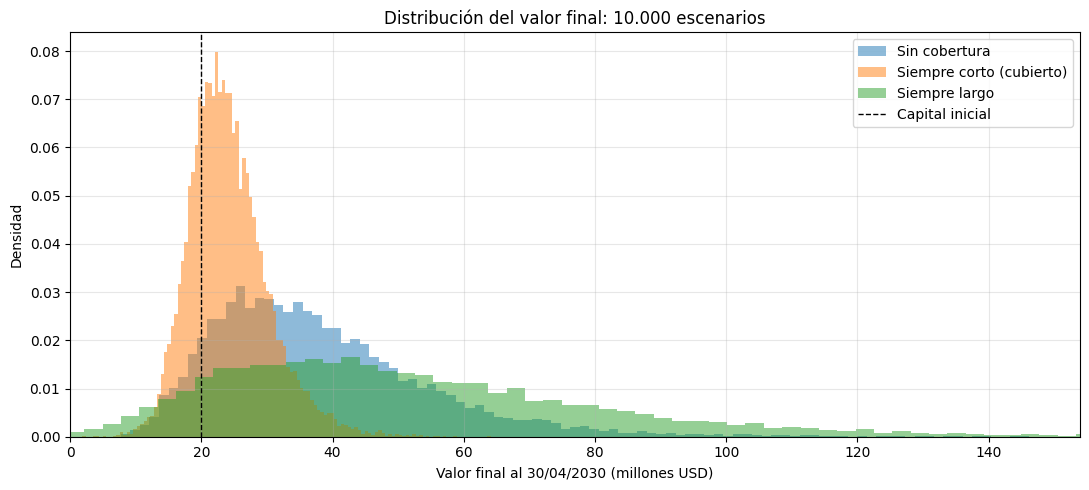

In [112]:
# 9.8 Gráfica: distribución del valor final a 4 años
fig, ax = plt.subplots(figsize=(11, 5))
for nombre, W in finales.items():
    ax.hist(W / 1e6, bins=120, alpha=0.5, density=True, label=nombre)
ax.axvline(CAPITAL / 1e6, color='black', ls='--', lw=1, label='Capital inicial')
ax.set_xlim(0, np.percentile(V + caja_larga, 99) / 1e6)
ax.set_xlabel('Valor final al 30/04/2030 (millones USD)'); ax.set_ylabel('Densidad')
ax.set_title('Distribución del valor final: 10.000 escenarios'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

10. Valor esperado de la cobertura trimestral con la tasa libre de riesgo (pregunta 10)
Tasa libre de riesgo: el enunciado sugiere ^TNX, pero en Yahoo Finance ^TNX es el rendimiento del Treasury a 10 años; el índice CBOE a 5 años es ^FVX. Se usa ^FVX (4,023% al 30/04/2026) por ser el plazo más cercano al horizonte de 4 años y por coherencia con las preguntas 3 y 5. Se muestra la sensibilidad con ^TNX y ^IRX.

Modelo (CAPM con la beta del portafolio cubierto)

Riesgo:(la cobertura elimina el riesgo de mercado, no el específico).

Trimestral:El valor esperado se proyecta trimestre a trimestre durante 16 trimestres.

In [113]:
# 10.1 Tasas libres de riesgo al 30/04/2026
tabla_rf = pd.DataFrame({
    'Instrumento': ['Treasury 10 años', 'Treasury 5 años', 'T-Bill 13 semanas'],
    'Ticker': ['^TNX', '^FVX', '^IRX'],
    'Tasa anual (%)': [tasas_inicio['^TNX'], tasas_inicio['^FVX'], tasas_inicio['^IRX']],
}).set_index('Ticker')
tabla_rf['Tasa trimestral (%)'] = ((1 + tabla_rf['Tasa anual (%)'] / 100) ** 0.25 - 1) * 100
display(tabla_rf.round(4))

RF_Q   = (1 + RF) ** 0.25 - 1
EM     = retornos[INDICE].mean() * DIAS_ANO
SIG_M_ = retornos[INDICE].std() * np.sqrt(DIAS_ANO)
SIG_EP = m_p.resid.std() * np.sqrt(DIAS_ANO)
BETA_CUB = BETA_P - N_OPT * F0 * MULT / CAPITAL
print(f'rf usada (^FVX): {RF:.4%} anual | {RF_Q:.4%} trimestral')
print(f'E(Rm) = {EM:.4%} | sigma_m = {SIG_M_:.4%} | sigma_e = {SIG_EP:.4%}')
print(f'Beta sin cobertura = {BETA_P:.4f} | beta cubierto ({N_OPT} contratos) = {BETA_CUB:.4f}')

,Instrumento,Tasa anual (%),Tasa trimestral (%)
Ticker,,,
^TNX,Treasury 10 años,4.390000,1.079900
^FVX,Treasury 5 años,4.023000,0.990900
^IRX,T-Bill 13 semanas,3.585000,0.884400


rf usada (^FVX): 4.0230% anual | 0.9909% trimestral
E(Rm) = 14.0973% | sigma_m = 18.0653% | sigma_e = 9.5417%
Beta sin cobertura = 1.0751 | beta cubierto (59 contratos) = 0.0066


In [114]:
# 10.2 Comparación: portafolio sin cobertura vs cubierto
def metricas(beta, nombre, rf=RF):
    rf_q = (1 + rf) ** 0.25 - 1
    er_a = rf + beta * (EM - rf)
    er_q = rf_q + beta * (EM / 4 - rf_q)
    sd_a = np.sqrt(beta**2 * SIG_M_**2 + SIG_EP**2)
    sd_q = sd_a / 2
    return pd.Series({
        'Beta': beta,
        'Retorno esperado trimestral (%)': er_q * 100,
        'Retorno esperado anual (%)': er_a * 100,
        'Desv. estándar trimestral (%)': sd_q * 100,
        'Desv. estándar anual (%)': sd_a * 100,
        'Sharpe anual': (er_a - rf) / sd_a,
        'Valor esperado a 1 trimestre (USD)': CAPITAL * (1 + er_q),
        'Ganancia esperada por trimestre (USD)': CAPITAL * er_q,
        'Valor esperado a 1 año (USD)': CAPITAL * (1 + er_q) ** 4,
        'Valor esperado a 4 años (USD)': CAPITAL * (1 + er_q) ** 16,
        'VaR 95% trimestral (USD)': -(er_q - norm.ppf(0.95) * sd_q) * CAPITAL,
        'VaR 99% trimestral (USD)': -(er_q - norm.ppf(0.99) * sd_q) * CAPITAL,
    }, name=nombre)

comp10 = pd.concat([metricas(BETA_P, 'Sin cobertura'), metricas(BETA_CUB, f'Cubierto ({N_OPT} futuros cortos)')], axis=1)
comp10['Diferencia'] = comp10.iloc[:, 1] - comp10.iloc[:, 0]
comp10.to_csv('valor_esperado_cobertura.csv')
comp10.round(4)

,Sin cobertura,Cubierto (59 futuros cortos),Diferencia
Beta,1.075100,0.006600,-1.068500
Retorno esperado trimestral (%),3.714600,1.007700,-2.706800
Retorno esperado anual (%),14.853800,4.089800,-10.763900
Desv. estándar trimestral (%),10.819500,4.771200,-6.048300
Desv. estándar anual (%),21.639100,9.542400,-12.096600
Sharpe anual,0.500500,0.007000,-0.493500
Valor esperado a 1 trimestre (USD),"20,742,910.713500","20,201,546.183500","-541,364.530000"
Ganancia esperada por trimestre (USD),"742,910.713500","201,546.183500","-541,364.530000"
Valor esperado a 1 año (USD),"23,141,356.074400","20,818,453.069100","-2,322,903.005300"
Valor esperado a 4 años (USD),"35,848,024.886300","23,480,310.528400","-12,367,714.358000"


In [115]:
# 10.3 Valor esperado trimestre a trimestre (16 trimestres) y aporte esperado de los futuros
er_sin_q = RF_Q + BETA_P * (EM / 4 - RF_Q)
er_cub_q = RF_Q + BETA_CUB * (EM / 4 - RF_Q)
filas, v_sin, v_cub = [], float(CAPITAL), float(CAPITAL)
for t in range(1, 17):
    g_acc = v_cub * er_sin_q
    g_fut = v_cub * (er_cub_q - er_sin_q)
    v_sin *= 1 + er_sin_q
    v_cub *= 1 + er_cub_q
    filas.append({'Trimestre': t, 'Valor esperado sin cobertura (USD)': v_sin,
                  'Valor esperado cubierto (USD)': v_cub,
                  'Ganancia esperada acciones (cubierto, USD)': g_acc,
                  'G/P esperada futuros cortos (USD)': g_fut,
                  'Valor libre de riesgo (USD)': CAPITAL * (1 + RF_Q) ** t})
trim = pd.DataFrame(filas).set_index('Trimestre')
trim.to_csv('valor_esperado_trimestral.csv')
trim.round(0)

,Valor esperado sin cobertura (USD),Valor esperado cubierto (USD),"Ganancia esperada acciones (cubierto, USD)",G/P esperada futuros cortos (USD),Valor libre de riesgo (USD)
Trimestre,,,,,
1,"20,742,911.000000","20,201,546.000000","742,911.000000","-541,365.000000","20,198,185.000000"
2,"21,513,417.000000","20,405,123.000000","750,397.000000","-546,820.000000","20,398,333.000000"
3,"22,312,545.000000","20,610,752.000000","757,959.000000","-552,331.000000","20,600,465.000000"
4,"23,141,356.000000","20,818,453.000000","765,597.000000","-557,897.000000","20,804,600.000000"
5,"24,000,954.000000","21,028,247.000000","773,313.000000","-563,519.000000","21,010,758.000000"
6,"24,892,482.000000","21,240,155.000000","781,106.000000","-569,197.000000","21,218,958.000000"
7,"25,817,127.000000","21,454,199.000000","788,977.000000","-574,933.000000","21,429,222.000000"
8,"26,776,118.000000","21,670,399.000000","796,928.000000","-580,727.000000","21,641,569.000000"
9,"27,770,731.000000","21,888,779.000000","804,959.000000","-586,579.000000","21,856,020.000000"


In [116]:
# 10.4 Sensibilidad a la tasa libre de riesgo elegida
sens = pd.DataFrame({tk: metricas(BETA_CUB, tk, rf=tabla_rf.loc[tk, 'Tasa anual (%)'] / 100)[
    ['Retorno esperado trimestral (%)', 'Retorno esperado anual (%)', 'Valor esperado a 1 trimestre (USD)',
     'Valor esperado a 4 años (USD)']] for tk in tabla_rf.index}).T
sens.index.name = 'Tasa usada (portafolio cubierto)'
sens.round(4)

,Retorno esperado trimestral (%),Retorno esperado anual (%),Valor esperado a 1 trimestre (USD),Valor esperado a 4 años (USD)
Tasa usada (portafolio cubierto),,,,
^TNX,1.096100,4.454400,"20,219,219.763100","23,811,148.708100"
^FVX,1.007700,4.089800,"20,201,546.183500","23,480,310.528400"
^IRX,0.902000,3.654700,"20,180,392.166800","23,089,987.165400"


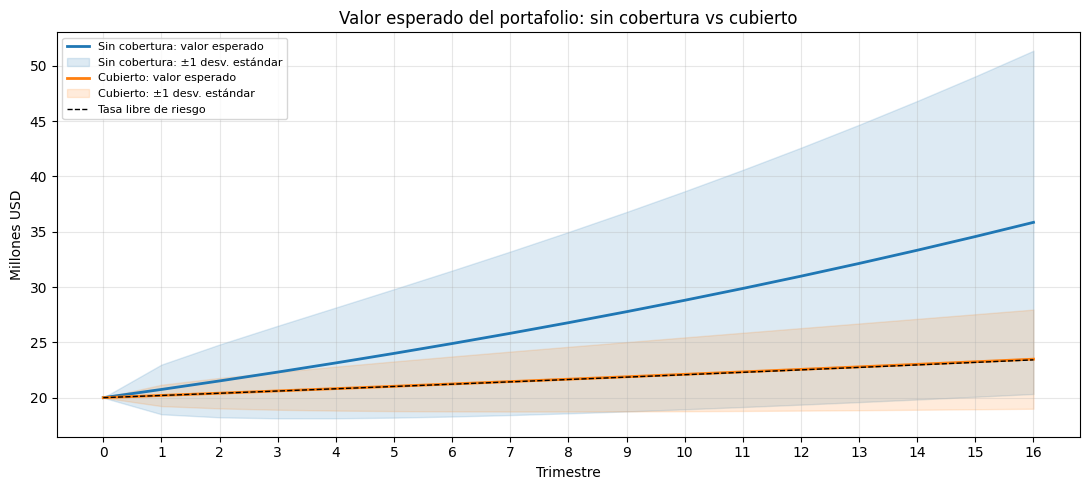

In [117]:
# 10.5 Gráfica: valor esperado con banda de +/- 1 desviación estándar
t_q = np.arange(0, 17)
fig, ax = plt.subplots(figsize=(11, 5))
for beta, nombre, col in [(BETA_P, 'Sin cobertura', 'tab:blue'), (BETA_CUB, 'Cubierto', 'tab:orange')]:
    m = metricas(beta, nombre)
    er_q, sd_q = m['Retorno esperado trimestral (%)'] / 100, m['Desv. estándar trimestral (%)'] / 100
    media = CAPITAL * (1 + er_q) ** t_q
    banda = media * sd_q * np.sqrt(t_q)
    ax.plot(t_q, media / 1e6, color=col, lw=2, label=f'{nombre}: valor esperado')
    ax.fill_between(t_q, (media - banda) / 1e6, (media + banda) / 1e6, color=col, alpha=0.15, label=f'{nombre}: ±1 desv. estándar')
ax.plot(t_q, CAPITAL * (1 + RF_Q) ** t_q / 1e6, 'k--', lw=1, label='Tasa libre de riesgo')
ax.set_xlabel('Trimestre'); ax.set_ylabel('Millones USD'); ax.set_xticks(t_q)
ax.set_title('Valor esperado del portafolio: sin cobertura vs cubierto'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 11. Rendimiento esperado mensual bajo tres enfoques y efecto de los dividendos

**Tres enfoques (horizonte mensual = 21 días):**
1. **Sin cobertura:** retorno mensual del portafolio con los pesos óptimos.
2. **Cubierto con futuros:** (razón de cobertura efectiva de 59 contratos). El término aproxima el retorno del futuro, cuyo precio incorpora el costo de financiamiento.
3. **Ajustado por escenarios de VaR:** valor de la cartera en los escenarios de pérdida del VaR al 95% y 99% y del Expected Shortfall, y valor esperado ponderado por la probabilidad de cada escenario (escenario normal, adverso y severo).

Se usan dos bases para el retorno esperado: **histórica** (media 2016–2026, incluye el alfa observado) y **CAPM** (sin alfa, más conservadora).

**Dividendos:** las tres empresas pagan dividendos trimestrales. Los precios ajustados ya incluyen su reinversión (retorno total). Se separa el retorno por precio del retorno por dividendos y se estima el dividendo esperado de la cartera con el último dividendo trimestral anualizado.

In [118]:
# 11.1 Dividendos: rendimiento esperado por acción y del portafolio
ult_div = pd.Series({t: dividendos[t].iloc[-1] for t in TICKERS})
fecha_div = pd.Series({t: dividendos[t].index[-1].date() for t in TICKERS})

precios_raw = yf.download(TICKERS, start=INICIO, end=FIN, auto_adjust=False, progress=False)['Close'][TICKERS]
precios_raw = precios_raw.loc[precios.index.intersection(precios_raw.index)]
precio0 = precios_raw.iloc[-1]

tabla_div = pd.DataFrame({
    'Último dividendo trimestral (USD)': ult_div, 'Fecha de pago': fecha_div,
    'Dividendo anual esperado (USD)': ult_div * 4,
    'Precio 30/04/2026 (USD)': precio0,
    'Rendimiento por dividendo (%)': ult_div * 4 / precio0 * 100,
    'Peso óptimo': W_OPT,
    'Acciones compradas': W_OPT * CAPITAL / precio0,
})
tabla_div['Dividendos esperados 12 meses (USD)'] = tabla_div['Acciones compradas'] * tabla_div['Dividendo anual esperado (USD)']
DY_P = (tabla_div['Peso óptimo'] * tabla_div['Rendimiento por dividendo (%)']).sum() / 100
display(tabla_div.round(4))
print(f'Rendimiento por dividendo del portafolio: {DY_P:.4%} anual | {DY_P/12:.4%} mensual')

,Último dividendo trimestral (USD),Fecha de pago,Dividendo anual esperado (USD),Precio 30/04/2026 (USD),Rendimiento por dividendo (%),Peso óptimo,Acciones compradas,Dividendos esperados 12 meses (USD)
MSFT,0.910000,2026-02-19,3.640000,407.780000,0.892600,0.567900,"27,851.096800","101,377.992200"
JPM,1.500000,2026-04-06,6.000000,313.230000,1.915500,0.332100,"21,207.673500","127,246.040800"
KO,0.530000,2026-03-13,2.120000,78.760000,2.691700,0.100000,"25,393.600100","53,834.432300"


Rendimiento por dividendo del portafolio: 1.4123% anual | 0.1177% mensual


In [119]:
# 11.2 Retorno por precio vs retorno total (efecto histórico de los dividendos)
ret_precio = precios_raw.pct_change().dropna()
ret_total  = ret_acc.loc[ret_precio.index]
desc = pd.DataFrame({
    'Retorno total anual (%)':   ret_total.mean() * DIAS_ANO * 100,
    'Retorno por precio anual (%)': ret_precio.mean() * DIAS_ANO * 100,
})
desc['Aporte de dividendos (pp)'] = desc['Retorno total anual (%)'] - desc['Retorno por precio anual (%)']
desc.loc['Portafolio'] = [(ret_total @ W_OPT).mean() * DIAS_ANO * 100, (ret_precio @ W_OPT).mean() * DIAS_ANO * 100, np.nan]
desc.loc['Portafolio', 'Aporte de dividendos (pp)'] = desc.loc['Portafolio'].iloc[0] - desc.loc['Portafolio'].iloc[1]
desc.round(4)

,Retorno total anual (%),Retorno por precio anual (%),Aporte de dividendos (pp)
Ticker,,,
MSFT,25.839600,24.560000,1.279600
JPM,22.367600,19.710200,2.657300
KO,10.414900,7.286300,3.128600
Portafolio,23.143900,21.221800,1.922100


In [120]:
# 11.3 Retornos mensuales históricos: sin cobertura, cubierto y solo precio
H_EF = N_OPT * F0 * MULT / CAPITAL
ret_cub_d = ret_port_d - H_EF * (retornos[INDICE] - rf_d)
mensual = lambda r: (1 + r).rolling(DIAS_MES).apply(np.prod, raw=True).dropna() - 1
m_sin, m_cub = mensual(ret_port_d), mensual(ret_cub_d)
m_precio = mensual(ret_precio @ W_OPT)
rf_m = (1 + RF) ** (1 / 12) - 1
EM_m = retornos[INDICE].mean() * DIAS_MES

print(f'Razón de cobertura efectiva h = {H_EF:.4f} | rf mensual = {rf_m:.4%}')
pd.DataFrame({'Media mensual (%)': [m_sin.mean()*100, m_cub.mean()*100, m_precio.mean()*100],
              'Desv. mensual (%)': [m_sin.std()*100, m_cub.std()*100, m_precio.std()*100]},
             index=['Sin cobertura (retorno total)', 'Cubierto (retorno total)', 'Sin cobertura (solo precio)']).round(4)

Razón de cobertura efectiva h = 1.0685 | rf mensual = 0.3292%


,Media mensual (%),Desv. mensual (%)
Sin cobertura (retorno total),1.876800,5.085300
Cubierto (retorno total),0.882800,2.376700
Sin cobertura (solo precio),1.713900,5.074000


In [121]:
# 11.4 Rendimiento esperado mensual y valor esperado bajo los tres enfoques
def enfoque(serie, er_m, nombre):
    sd = serie.std()
    v95, v99 = -(er_m - norm.ppf(0.95) * sd), -(er_m - norm.ppf(0.99) * sd)
    es99 = -serie[serie <= serie.quantile(0.01)].mean()
    return pd.Series({
        'Retorno esperado mensual (%)': er_m * 100, 'Desv. mensual (%)': sd * 100,
        'Valor esperado a 1 mes (USD)': CAPITAL * (1 + er_m),
        'Valor esperado a 12 meses (USD)': CAPITAL * (1 + er_m) ** 12,
        'VaR 95% mensual (%)': v95 * 100, 'VaR 99% mensual (%)': v99 * 100,
        'Valor en escenario VaR 95% (USD)': CAPITAL * (1 - v95),
        'Valor en escenario VaR 99% (USD)': CAPITAL * (1 - v99),
        'Valor en escenario ES 99% hist. (USD)': CAPITAL * (1 - es99),
        'Retorno esperado / VaR 95%': er_m / v95,
    }, name=nombre)

er_sin_hist = m_sin.mean()
er_cub_hist = er_sin_hist - H_EF * (EM_m - rf_m)
er_sin_capm = rf_m + BETA_P * (EM_m - rf_m)
er_cub_capm = rf_m + BETA_CUB * (EM_m - rf_m)

tres = pd.concat([enfoque(m_sin, er_sin_hist, 'Sin cobertura (histórico)'),
                  enfoque(m_cub, er_cub_hist, 'Cubierto (histórico)'),
                  enfoque(m_sin, er_sin_capm, 'Sin cobertura (CAPM)'),
                  enfoque(m_cub, er_cub_capm, 'Cubierto (CAPM)')], axis=1)
tres.to_csv('tres_enfoques_mensual.csv')
tres.round(4)

,Sin cobertura (histórico),Cubierto (histórico),Sin cobertura (CAPM),Cubierto (CAPM)
Retorno esperado mensual (%),1.876800,0.973400,1.238300,0.334800
Desv. mensual (%),5.085300,2.376700,5.085300,2.376700
Valor esperado a 1 mes (USD),"20,375,361.470500","20,194,674.758800","20,247,653.199500","20,066,966.487800"
Valor esperado a 12 meses (USD),"24,999,649.108700","22,465,309.447500","23,182,825.777600","20,818,563.160300"
VaR 95% mensual (%),6.487800,2.936000,7.126400,3.574500
VaR 99% mensual (%),9.953400,4.555700,10.592000,5.194200
Valor en escenario VaR 95% (USD),"18,702,436.484000","19,412,803.129400","18,574,728.213000","19,285,094.858400"
Valor en escenario VaR 99% (USD),"18,009,311.737000","19,088,858.792500","17,881,603.466000","18,961,150.521500"
Valor en escenario ES 99% hist. (USD),"16,080,328.653900","18,640,202.685500","16,080,328.653900","18,640,202.685500"
Retorno esperado / VaR 95%,0.289300,0.331500,0.173800,0.093700


In [122]:
# 11.5 Valor esperado ponderado por escenarios de VaR (distribución histórica mensual)
def escenarios(serie, nombre):
    q01, q05 = serie.quantile(0.01), serie.quantile(0.05)
    grupos = {'Severo (peor 1%)': serie[serie <= q01],
              'Adverso (1%-5%)': serie[(serie > q01) & (serie <= q05)],
              'Normal (resto 95%)': serie[serie > q05]}
    filas = []
    for g, s in grupos.items():
        p = len(s) / len(serie)
        filas.append({'Portafolio': nombre, 'Escenario': g, 'Probabilidad (%)': p * 100,
                      'Retorno medio del escenario (%)': s.mean() * 100,
                      'Valor de la cartera (USD)': CAPITAL * (1 + s.mean()),
                      'Aporte al retorno esperado (pp)': p * s.mean() * 100})
    df = pd.DataFrame(filas)
    tot = {'Portafolio': nombre, 'Escenario': 'Valor esperado ponderado', 'Probabilidad (%)': 100,
           'Retorno medio del escenario (%)': df['Aporte al retorno esperado (pp)'].sum(),
           'Valor de la cartera (USD)': CAPITAL * (1 + df['Aporte al retorno esperado (pp)'].sum() / 100),
           'Aporte al retorno esperado (pp)': df['Aporte al retorno esperado (pp)'].sum()}
    return pd.concat([df, pd.DataFrame([tot])])

tabla_esc = pd.concat([escenarios(m_sin, 'Sin cobertura'), escenarios(m_cub, 'Cubierto')]).set_index(['Portafolio', 'Escenario'])
tabla_esc.to_csv('escenarios_var_mensual.csv')
tabla_esc.round(4)

Probabilidad (%)  \
Portafolio    Escenario                                    
Sin cobertura Severo (peor 1%)                  1.002800   
              Adverso (1%-5%)                   4.011200   
              Normal (resto 95%)               94.986000   
              Valor esperado ponderado        100.000000   
Cubierto      Severo (peor 1%)                  1.002800   
              Adverso (1%-5%)                   4.011200   
              Normal (resto 95%)               94.986000   
              Valor esperado ponderado        100.000000   

                                        Retorno medio del escenario (%)  \
Portafolio    Escenario                                                   
Sin cobertura Severo (peor 1%)                               -19.598400   
              Adverso (1%-5%)                                 -8.598900   
              Normal (resto 95%)                               2.545900   
              Valor esperado ponderado                         1.876800   
Cubierto      Severo (peor 1%)                                -6.799000   
              Adverso (1%-5%)                                 -3.580200   
              Normal (resto 95%)                               1.152400   
              Valor esperado ponderado                         0.882800   

                                        Valor de la cartera (USD)  \
Portafolio    Escenario                                             
Sin cobertura Severo (peor 1%)                  16,080,328.653900   
              Adverso (1%-5%)                   18,280,210.664400   
              Normal (resto 95%)                20,509,183.641500   
              Valor esperado ponderado          20,375,361.470500   
Cubierto      Severo (peor 1%)                  18,640,202.685500   
              Adverso (1%-5%)                   19,283,956.459600   
              Normal (resto 95%)                20,230,472.431700   
              Valor esperado ponderado          20,176,558.135300   

                                        Aporte al retorno esperado (pp)  
Portafolio    Escenario                                                  
Sin cobertura Severo (peor 1%)                                -0.196500  
              Adverso (1%-5%)                                 -0.344900  
              Normal (resto 95%)                               2.418300  
              Valor esperado ponderado                         1.876800  
Cubierto      Severo (peor 1%)                                -0.068200  
              Adverso (1%-5%)                                 -0.143600  
              Normal (resto 95%)                               1.094600  
              Valor esperado ponderado                         0.882800

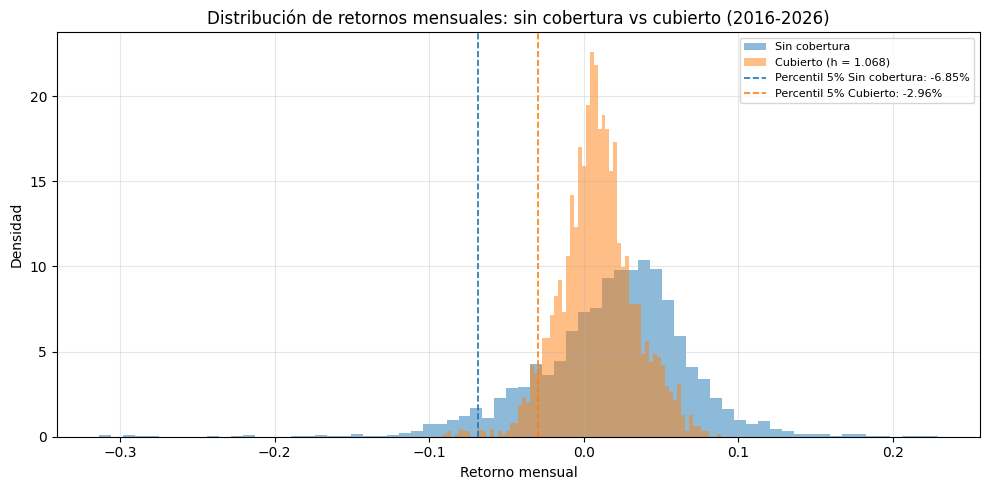

In [123]:
# 11.6 Gráfica: distribución mensual sin cobertura vs cubierto
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(m_sin, bins=70, alpha=0.5, density=True, label='Sin cobertura')
ax.hist(m_cub, bins=70, alpha=0.5, density=True, label=f'Cubierto (h = {H_EF:.3f})')
for s, c, n in [(m_sin, 'tab:blue', 'Sin cobertura'), (m_cub, 'tab:orange', 'Cubierto')]:
    ax.axvline(s.quantile(0.05), color=c, ls='--', lw=1.2, label=f'Percentil 5% {n}: {s.quantile(0.05):.2%}')
ax.set_xlabel('Retorno mensual'); ax.set_ylabel('Densidad')
ax.set_title('Distribución de retornos mensuales: sin cobertura vs cubierto (2016-2026)')
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 12. Sensibilidad de la cobertura a la beta del portafolio

Se comparan tres portafolios hipotéticos de USD 20.000.000 que solo difieren en su beta: $\beta = 0{,}5$, la beta real  y $\beta = 2$. El riesgo específico se mantiene en el del portafolio real ($\sigma_\varepsilon$).

- **Número óptimo de contratos:**  redondeado al entero con menor beta residual.
- **Exposición sistemática: **Sensibilidad:** cambio del portafolio por cada 1% de movimiento del índice
- **Efectividad de la cobertura:** proporción de la varianza eliminada.
- **Liquidez:** margen inicial y reposiciones que habría exigido la cuenta de margen en el período real (pregunta 8), que escalan con el número de contratos.

In [124]:
# 12.1 Número óptimo de contratos, exposición y efectividad para cada beta
gp_corta_por_contrato = flujos['G/P corta (USD)'].sum() / N_OPT
repos_por_contrato    = flujos['Reposición (USD)'].sum() / N_OPT

filas = []
for b in [0.5, BETA_P, 2.0]:
    n_exacto = b * CAPITAL / (F0 * MULT)
    cand = [int(np.floor(n_exacto)), int(np.ceil(n_exacto))]
    res = [b - n * F0 * MULT / CAPITAL for n in cand]
    n = cand[int(np.argmin(np.abs(res)))]
    b_res = b - n * F0 * MULT / CAPITAL
    var_sin = b**2 * SIG_M_**2 + SIG_EP**2
    var_cub = b_res**2 * SIG_M_**2 + SIG_EP**2
    filas.append({
        'Beta': b, 'N* exacto': n_exacto, 'Contratos (redondeo)': n,
        'Redondeo': 'abajo' if n == cand[0] else 'arriba', 'Beta residual': b_res,
        'Exposición sistemática (USD)': b * CAPITAL,
        'Sensibilidad por 1% del índice (USD)': b * CAPITAL * 0.01,
        'Nocional cubierto (USD)': n * F0 * MULT,
        'Volatilidad anual sin cobertura (%)': np.sqrt(var_sin) * 100,
        'Volatilidad anual cubierto (%)': np.sqrt(var_cub) * 100,
        'Varianza eliminada (%)': (1 - var_cub / var_sin) * 100,
        'Retorno esperado CAPM sin cobertura (%)': (RF + b * (EM - RF)) * 100,
        'Retorno esperado CAPM cubierto (%)': (RF + b_res * (EM - RF)) * 100,
        'Margen inicial total (USD)': n * MARGEN_INI,
        'G/P real futuros cortos abr-oct 2026 (USD)': n * gp_corta_por_contrato,
        'Reposiciones reales al margen (USD)': n * repos_por_contrato,
    })
tabla12 = pd.DataFrame(filas).set_index('Beta')
tabla12.to_csv('sensibilidad_beta.csv')
tabla12.round(4).T

Beta,0.500000,1.075087,2.000000
N* exacto,27.610000,59.366300,110.440000
Contratos (redondeo),28,59,110
Redondeo,arriba,abajo,abajo
Beta residual,-0.007100,0.006600,0.008000
Exposición sistemática (USD),"10,000,000.000000","21,501,749.299400","40,000,000.000000"
Sensibilidad por 1% del índice (USD),"100,000.000000","215,017.493000","400,000.000000"
Nocional cubierto (USD),"10,141,250.000000","21,369,062.500000","39,840,625.000000"
Volatilidad anual sin cobertura (%),13.139000,21.639100,37.369300
Volatilidad anual cubierto (%),9.542500,9.542400,9.542800
Varianza eliminada (%),47.252100,80.553500,93.478900


In [125]:
# 12.2 Escenarios de mercado: portafolio, futuros cortos y resultado neto para cada beta
movs12 = [-0.20, -0.10, 0.10, 0.20]
filas = []
for b, fila in tabla12.iterrows():
    n = fila['Contratos (redondeo)']
    for dm in movs12:
        port = b * dm * CAPITAL
        fut = -n * F0 * MULT * dm
        filas.append({'Beta': round(b, 4), 'Mov. S&P 500': f'{dm:+.0%}', 'Portafolio (USD)': port,
                      'Futuros cortos (USD)': fut, 'Neto (USD)': port + fut})
esc12 = pd.DataFrame(filas).set_index(['Beta', 'Mov. S&P 500'])
esc12.round(0)

Portafolio (USD)  Futuros cortos (USD)     Neto (USD)
Beta     Mov. S&P 500                                                       
0.500000 -20%         -2,000,000.000000      2,028,250.000000  28,250.000000
         -10%         -1,000,000.000000      1,014,125.000000  14,125.000000
         +10%          1,000,000.000000     -1,014,125.000000 -14,125.000000
         +20%          2,000,000.000000     -2,028,250.000000 -28,250.000000
1.075100 -20%         -4,300,350.000000      4,273,812.000000 -26,537.000000
         -10%         -2,150,175.000000      2,136,906.000000 -13,269.000000
         +10%          2,150,175.000000     -2,136,906.000000  13,269.000000
         +20%          4,300,350.000000     -4,273,812.000000  26,537.000000
2.000000 -20%         -8,000,000.000000      7,968,125.000000 -31,875.000000
         -10%         -4,000,000.000000      3,984,062.000000 -15,938.000000
         +10%          4,000,000.000000     -3,984,062.000000  15,938.000000
         +20%          8,000,000.000000     -7,968,125.000000  31,875.000000